In [1]:
## LAI analysis and scaling in Fynbos using UAS MSI + AVIRIS-NG HSI
## Author: Ramesh Bhatta, CIS, RIT
## Contact: rb1005@rit.edu

"""

This notebook follows the cross-platform modeling chain used in the paper:
(1) establish the UAS MSI LAI baseline, 
(2) apply the four-anchor UAS-guided adjustment to
full-spectrum AVIRIS-NG,
(3) compare raw and adjusted HSI relationships, and
(4) apply the fixed raw SWIR model at landscape scale.

"""

'\n\nThis notebook follows the cross-platform modeling chain used in the paper:\n(1) establish the UAS MSI LAI baseline, \n(2) apply the four-anchor UAS-guided adjustment to\nfull-spectrum AVIRIS-NG,\n(3) compare raw and adjusted HSI relationships, and\n(4) apply the fixed raw SWIR model at landscape scale.\n\n'

In [2]:
## Necessary imports and global settings

from pathlib import Path
from tempfile import TemporaryDirectory
import os
import re

import numpy as np
import pandas as pd
import geopandas as gpd

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
from matplotlib.lines import Line2D

import rasterio
from rasterio.io import MemoryFile
from rasterio.mask import mask as raster_mask
from rasterio.windows import Window
from rasterio.features import geometry_mask, geometry_window
from rasterio.errors import WindowError
from rasterio.merge import merge
from rasterstats import zonal_stats

from netCDF4 import Dataset

from shapely.geometry import Polygon, box, mapping
from shapely.ops import transform as shapely_transform

from pyproj import Transformer

from scipy.stats import pearsonr
from scipy.spatial import cKDTree

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

from IPython.display import display

pd.set_option("display.max_columns", 100); pd.set_option("display.width", 200)

# Input data used by the final revision analysis
UAS_FILES = {
    "BY_2006": "../Drone_msi_data/burn2006_lr_band_stack.tif", "BY_2016": "../Drone_msi_data/burn2016_lr_band_stack.tif",
    "BY_2019": "../Drone_msi_data/burn2019_lr_band_stack.tif", "BY_2020": "../Drone_msi_data/burn2020_lr_band_stack.tif",
    "BY_2017_16": "../Drone_msi_data/burn2017_2016_lr_band_stack.tif",
}

AVIRIS_L2B = {
    "ang20231031t092656_002": Path("../../AVIRIS_NG_data/ang20231031t092656_002_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.nc"),
    "ang20231109t062226_001": Path("../../AVIRIS_NG_data/ang20231109t062226_001_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.nc"),
    "ang20231109t062226_002": Path("../../AVIRIS_NG_data/ang20231109t062226_002_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.nc"),
    "ang20231117t123306_001": Path("../../AVIRIS_NG_data/ang20231117t123306_001_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.nc"),
}

SRF_FILES = {
    "Green": Path("../Mavic3m_srf/Mavic3-MS_G_filter.csv"), "Red": Path("../Mavic3m_srf/Mavic3-MS_R_filter.csv"),
    "RedEdge": Path("../Mavic3m_srf/Mavic3-MS_RE_filter.csv"), "NIR": Path("../Mavic3m_srf/Mavic3-MS_IR_filter.csv"),
}

LAI_SHAPEFILE = Path("./ground_LAI_data_processed/5mx5m_LAI_plots.shp")

ANCHOR_BANDS = ["Green", "Red", "RedEdge", "NIR"]
ANCHOR_WAVELENGTHS = None
EPS, VALID_TOL = 1e-6, 1e-12
STRICT_INTERIOR_VALID_FRACTION = 1.0
N_SPATIAL_FOLDS, PRIMARY_BUFFER_PIXELS = 5, 1
EXPECTED_LAI_N, EXPECTED_COMMON_UAS_N = 20, 11
EXPECTED_STRICT_INTERIOR_N, EXPECTED_DEPLOY_N = 2147, 2006

ANCHOR_RF_KWARGS = {
    "n_estimators": 300, "min_samples_leaf": 10, "max_features": 4,
    "max_depth": 6, "random_state": 42, "n_jobs": -1,
}

BAND_COLORS = {"Green": "#2ca02c", "Red": "#d62728", "RedEdge": "#9467bd", "NIR": "#1f77b4"}
RECOVERY_COLORS = {"Mature": "#1f77b4", "Mid-recovery": "#2ca02c", "Young": "#ff7f0e"}


# Final revision settings used below
HSI_INDEX_NAMES = [
    "NDVI", "SR", "GNDVI", "GRVI", "GDVI", "SAVI", "GSAVI", "OSAVI", "MSAVI2",
    "NDRE", "SR_RE", "CI_RE", "MTCI", "MSR", "EVI2", "NDWI", "CAI", "NDLI",
    "Custom_SWIR_Primary", "Custom_NIR_Plateau", "Custom_VIS_Green", "Custom_SWIR1_Bridge",
    "NIRv", "SATVI", "NDTI", "SINDRI", "LCA", "MTVI2",
]
PRIMARY_HSI_INDEX, PRIMARY_HSI_FORM = "Custom_SWIR_Primary", "Linear"
TARGET_MAP = {"Green":"UAS_Green", "Red":"UAS_Red", "RedEdge":"UAS_RedEdge", "NIR":"UAS_NIR"}

In [3]:
## A1. Shared spectral, index, spatial, and LAI-model helpers

def read_wavelengths(nc_path):
    with Dataset(nc_path, mode='r') as ds:
        return np.asarray(ds.groups['reflectance'].variables['wavelength'][:], dtype=float)

def load_srf_curve(csv_path):
    df = pd.read_csv(csv_path)
    if df.shape[1] < 2:
        raise ValueError(f'{csv_path} must contain wavelength and response columns.')
    wl = df.iloc[:, 0].to_numpy(dtype=float)
    response = df.iloc[:, 1].to_numpy(dtype=float)
    valid = np.isfinite(wl) & np.isfinite(response)
    wl = wl[valid]
    response = response[valid]
    if np.nanmedian(wl) < 10:
        wl = wl * 1000.0
    order = np.argsort(wl)
    return (wl[order], response[order])

scene_wavelengths = {scene: read_wavelengths(path) for scene, path in AVIRIS_L2B.items()}
reference_scene = next(iter(scene_wavelengths))
wavelengths = scene_wavelengths[reference_scene].copy()
for scene, wl in scene_wavelengths.items():
    if len(wl) != len(wavelengths) or not np.allclose(wl, wavelengths, atol=1e-06, rtol=0):
        raise RuntimeError(f'{scene} does not share the common AVIRIS wavelength grid.')
    
native_srf = {band: load_srf_curve(path) for band, path in SRF_FILES.items()}
srf_effective_wavelengths = {}
for band in ANCHOR_BANDS:
    srf_wl, srf_response = native_srf[band]
    response = np.clip(np.asarray(srf_response, dtype=float), 0, None)
    if response.sum() <= 0:
        raise RuntimeError(f'{band}: invalid measured SRF.')
    srf_effective_wavelengths[band] = float(np.sum(np.asarray(srf_wl, dtype=float) * response) / np.sum(response))
ANCHOR_WAVELENGTHS = np.array([srf_effective_wavelengths[band] for band in ANCHOR_BANDS], dtype=float)
if not np.all(np.diff(ANCHOR_WAVELENGTHS) > 0):
    raise RuntimeError('Measured SRF effective wavelengths are not strictly increasing.')

srf_weights = {}
for band in ANCHOR_BANDS:
    srf_wl, srf_response = native_srf[band]
    response = np.interp(wavelengths, srf_wl, srf_response, left=0.0, right=0.0)
    response = np.clip(response, 0, None)
    if response.sum() <= 0:
        raise RuntimeError(f'No AVIRIS overlap with the {band} Mavic SRF.')
    full_weights = response / response.sum()
    idx = np.where(full_weights > 0)[0]
    srf_weights[band] = {'indices': idx, 'weights': full_weights[idx], 'full_weights': full_weights}

def synthesize_srf_anchors(spectrum):
    """
    Integrate one AVIRIS spectrum through the measured Mavic SRFs.
    """
    spectrum = np.asarray(spectrum, dtype=float)
    out = {}
    for band in ANCHOR_BANDS:
        info = srf_weights[band]
        vals = spectrum[info['indices']]
        if not np.isfinite(vals).all():
            out[band] = np.nan
        else:
            out[band] = float(np.sum(vals * info['weights']))
    return out

def synthesize_srf_anchor_matrix(spectra):
    """
    Vectorized Mavic-SRF integration for an n × wavelength matrix.
    """
    spectra = np.asarray(spectra, dtype=float)
    if spectra.ndim != 2:
        raise ValueError('spectra must be a 2-D [sample, wavelength] array.')
    out = {}
    for band in ANCHOR_BANDS:
        info = srf_weights[band]
        vals = spectra[:, info['indices']]
        out[band] = np.sum(vals * info['weights'][None, :], axis=1)
    return out

gain_basis_columns = []
for j in range(len(ANCHOR_BANDS)):
    knot_values = np.zeros(len(ANCHOR_BANDS), dtype=float)
    knot_values[j] = 1.0
    basis_j = np.interp(wavelengths, ANCHOR_WAVELENGTHS, knot_values, left=knot_values[0], right=knot_values[-1])
    gain_basis_columns.append(basis_j)
GAIN_BASIS = np.column_stack(gain_basis_columns)
if not np.allclose(GAIN_BASIS.sum(axis=1), 1.0, atol=1e-12):
    raise RuntimeError('Piecewise-linear gain basis does not form a partition of unity.')

def solve_srf_constrained_gain(spectrum, target_anchors):
    """
    Solve the four gain-knot coefficients so that the SRF-integrated
    harmonized spectrum reproduces the four RF-predicted UAS bands.

    The harmonized spectrum is:

        Rh(λ) = Rraw(λ) * Σ_j c_j B_j(λ)

    and the four coefficients c_j are obtained from a 4 × 4 linear
    system formed by integrating Rraw(λ) B_j(λ) through each Mavic SRF.
    """
    spectrum = np.asarray(spectrum, dtype=float)
    target = np.asarray([target_anchors[band] for band in ANCHOR_BANDS], dtype=float)
    if not np.isfinite(target).all():
        raise ValueError('Non-finite target anchors.')
    M = np.zeros((len(ANCHOR_BANDS), len(ANCHOR_BANDS)), dtype=float)
    for i, band in enumerate(ANCHOR_BANDS):
        info = srf_weights[band]
        idx = info['indices']
        w = info['weights']
        raw_vals = spectrum[idx]
        if not np.isfinite(raw_vals).all():
            raise ValueError(f'Non-finite spectrum within {band} SRF.')
        for j in range(len(ANCHOR_BANDS)):
            M[i, j] = np.sum(raw_vals * GAIN_BASIS[idx, j] * w)
    condition_number = float(np.linalg.cond(M))
    try:
        knot_gains = np.linalg.solve(M, target)
        solver = 'solve'
    except np.linalg.LinAlgError:
        knot_gains = np.linalg.lstsq(M, target, rcond=None)[0]
        solver = 'lstsq'
    gain_curve = GAIN_BASIS @ knot_gains
    harmonized_spectrum = spectrum * gain_curve
    reconstructed = synthesize_srf_anchors(harmonized_spectrum)
    reconstructed_vector = np.asarray([reconstructed[band] for band in ANCHOR_BANDS], dtype=float)
    residual = reconstructed_vector - target
    return {'harmonized_spectrum': harmonized_spectrum, 'gain_curve': gain_curve, 'knot_gains': knot_gains, 'condition_number': condition_number, 'solver': solver, 'reconstructed_anchors': reconstructed, 'anchor_residuals': residual, 'max_abs_anchor_residual': float(np.max(np.abs(residual)))}

print(f'Verified common AVIRIS wavelength grid: {len(wavelengths)} bands.')
print('\nMeasured Mavic SRF effective wavelengths:')
display(pd.DataFrame({'Band': ANCHOR_BANDS, 'Effective_wavelength_nm': ANCHOR_WAVELENGTHS}).round(3))

def prediction_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    valid = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true = y_true[valid]
    y_pred = y_pred[valid]
    if len(y_true) < 2:
        return {'n': len(y_true), 'R2': np.nan, 'RMSE': np.nan, 'MAE': np.nan, 'Bias': np.nan, 'r': np.nan}
    return {'n': len(y_true), 'R2': r2_score(y_true, y_pred), 'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)), 'MAE': mean_absolute_error(y_true, y_pred), 'Bias': float(np.mean(y_pred - y_true)), 'r': float(np.corrcoef(y_true, y_pred)[0, 1])}

def centered_r(y_true, y_pred, groups):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    groups = np.asarray(groups)
    valid = np.isfinite(y_true) & np.isfinite(y_pred) & pd.notna(groups)
    y_true = y_true[valid]
    y_pred = y_pred[valid]
    groups = groups[valid]
    yc = np.full(len(y_true), np.nan)
    pc = np.full(len(y_pred), np.nan)
    for g in np.unique(groups):
        m = groups == g
        yc[m] = y_true[m] - np.mean(y_true[m])
        pc[m] = y_pred[m] - np.mean(y_pred[m])
    if np.std(yc) <= 0 or np.std(pc) <= 0:
        return np.nan
    return float(np.corrcoef(yc, pc)[0, 1])

def fit_predict_form(x_train, y_train, x_test, form):
    degree = 1 if form == 'Linear' else 2
    coef = np.polyfit(np.asarray(x_train, dtype=float), np.asarray(y_train, dtype=float), degree)
    return np.polyval(coef, np.asarray(x_test, dtype=float))

def evaluate_single_index(x, y, form):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    valid = np.isfinite(x) & np.isfinite(y)
    x = x[valid]
    y = y[valid]
    degree = 1 if form == 'Linear' else 2
    coef = np.polyfit(x, y, degree)
    fitted = np.polyval(coef, x)
    loo = LeaveOneOut()
    cv_pred = np.full(len(y), np.nan, dtype=float)
    for tr, te in loo.split(x):
        cv_pred[te] = fit_predict_form(x[tr], y[tr], x[te], form)
    return {'n': len(y), 'Full_R2': r2_score(y, fitted), 'Full_RMSE': np.sqrt(mean_squared_error(y, fitted)), 'LOOCV_R2': r2_score(y, cv_pred), 'LOOCV_RMSE': np.sqrt(mean_squared_error(y, cv_pred)), 'LOOCV_MAE': mean_absolute_error(y, cv_pred), 'LOOCV_pred': cv_pred}

def calculate_hsi_indices(X_mat, wave_arr):
    X_mat = np.asarray(X_mat, dtype=float)
    wave_arr = np.asarray(wave_arr, dtype=float)
    targets = [480, 527.4, 531, 547.4, 550, 570, 670, 681, 709, 720, 754, 800, 850, 860, 1240, 1243.6, 1288.7, 1650, 1680, 1729.5, 1749.5, 1750, 2005, 2100, 2210, 2260, 2320.5, 2330]
    b = {w: X_mat[:, np.argmin(np.abs(wave_arr - w))] for w in targets}
    ndvi = (b[850] - b[670]) / (b[850] + b[670] + EPS)
    return {'NDVI': ndvi, 'SR': b[850] / (b[670] + EPS), 'GNDVI': (b[850] - b[550]) / (b[850] + b[550] + EPS), 'GRVI': (b[550] - b[670]) / (b[550] + b[670] + EPS), 'GDVI': b[850] - b[550], 'SAVI': 1.5 * (b[850] - b[670]) / (b[850] + b[670] + 0.5 + EPS), 'GSAVI': 1.5 * (b[850] - b[550]) / (b[850] + b[550] + 0.5 + EPS), 'OSAVI': 1.16 * (b[850] - b[670]) / (b[850] + b[670] + 0.16 + EPS), 'MSAVI2': 0.5 * (2 * b[850] + 1 - np.sqrt(np.maximum((2 * b[850] + 1) ** 2 - 8 * (b[850] - b[670]), 0))), 'NDRE': (b[850] - b[720]) / (b[850] + b[720] + EPS), 'SR_RE': b[850] / (b[720] + EPS), 'CI_RE': b[850] / (b[720] + EPS) - 1, 'MTCI': (b[754] - b[709]) / (b[709] - b[681] + EPS), 'MSR': (b[850] / (b[670] + EPS) - 1) / (np.sqrt(np.maximum(b[850] / (b[670] + EPS), 0)) + 1), 'EVI2': 2.5 * (b[850] - b[670]) / (b[850] + 2.4 * b[670] + 1 + EPS), 'NDWI': (b[860] - b[1240]) / (b[860] + b[1240] + EPS), 'CAI': 0.5 * (b[2005] + b[2210]) - b[2100], 'NDLI': (np.log(1 / (b[1750] + EPS)) - np.log(1 / (b[1680] + EPS))) / (np.log(1 / (b[1750] + EPS)) + np.log(1 / (b[1680] + EPS)) + EPS), 'Custom_SWIR_Primary': (b[2320.5] - b[2005]) / (b[2320.5] + b[2005] + EPS), 'Custom_NIR_Plateau': (b[1288.7] - b[1243.6]) / (b[1288.7] + b[1243.6] + EPS), 'Custom_VIS_Green': (b[547.4] - b[527.4]) / (b[547.4] + b[527.4] + EPS), 'Custom_SWIR1_Bridge': (b[1749.5] - b[1729.5]) / (b[1749.5] + b[1729.5] + EPS), 'NIRv': ndvi * b[850], 'SATVI': 1.5 * (b[1650] - b[670]) / (b[1650] + b[670] + 0.5 + EPS) - b[2210] / 2.0, 'NDTI': (b[1650] - b[2210]) / (b[1650] + b[2210] + EPS), 'SINDRI': (b[2210] - b[2260]) / (b[2210] + b[2260] + EPS), 'LCA': 100 * (2.0 * b[2210] - (b[2100] + b[2330])), 'MTVI2': 1.5 * (1.2 * (b[800] - b[550]) - 2.5 * (b[670] - b[550])) / np.sqrt(np.maximum((2 * b[800] + 1) ** 2 - (6 * b[800] - 5 * np.sqrt(np.maximum(b[670], 0))) - 0.5, EPS))}

def calculate_uas_indices(G, R, RE, NIR):
    G = np.asarray(G, dtype=float)
    R = np.asarray(R, dtype=float)
    RE = np.asarray(RE, dtype=float)
    NIR = np.asarray(NIR, dtype=float)
    ndvi = (NIR - R) / (NIR + R + EPS)
    msavi_term = (2 * NIR + 1) ** 2 - 8 * (NIR - R)
    mtvi_term = (2 * NIR + 1) ** 2 - (6 * NIR - 5 * np.sqrt(np.maximum(R, 0))) - 0.5
    return {'NDVI': ndvi, 'SR': NIR / (R + EPS), 'GNDVI': (NIR - G) / (NIR + G + EPS), 'GRVI': (G - R) / (G + R + EPS), 'GDVI': NIR - G, 'SAVI': 1.5 * (NIR - R) / (NIR + R + 0.5 + EPS), 'GSAVI': 1.5 * (NIR - G) / (NIR + G + 0.5 + EPS), 'OSAVI': 1.16 * (NIR - R) / (NIR + R + 0.16 + EPS), 'MSAVI2': 0.5 * (2 * NIR + 1 - np.sqrt(np.maximum(msavi_term, 0))), 'NDRE': (NIR - RE) / (NIR + RE + EPS), 'SR_RE': NIR / (RE + EPS), 'CI_RE': NIR / (RE + EPS) - 1, 'MTCI': (NIR - RE) / (RE - R + EPS), 'MSR': (NIR / (R + EPS) - 1) / (np.sqrt(np.maximum(NIR / (R + EPS), 0)) + 1), 'EVI2': 2.5 * (NIR - R) / (NIR + 2.4 * R + 1 + EPS), 'NIRv': ndvi * NIR, 'MTVI2': 1.5 * (1.2 * (NIR - G) - 2.5 * (R - G)) / np.sqrt(np.maximum(mtvi_term, EPS))}
print(f'HSI index suite initialized: {len(HSI_INDEX_NAMES)} indices.')

def aviris_pixel_polygon(src, row, col):
    t = src.transform
    return Polygon([t * (col, row), t * (col + 1, row), t * (col + 1, row + 1), t * (col, row + 1)])

def aggregate_uas_inside_polygon(src, polygon):
    try:
        win = geometry_window(src, [mapping(polygon)], pad_x=0, pad_y=0)
    except WindowError:
        return None
    if win.width <= 0 or win.height <= 0:
        return None
    data = src.read(indexes=[1, 2, 3, 4], window=win).astype(float)
    masks = src.read_masks(indexes=[1, 2, 3, 4], window=win)
    if data.size == 0:
        return None
    inside = geometry_mask([mapping(polygon)], out_shape=(data.shape[1], data.shape[2]), transform=src.window_transform(win), invert=True, all_touched=False)
    n_inside = int(inside.sum())
    if n_inside == 0:
        return None
    support_valid = inside.copy()
    support_valid &= np.all(masks > 0, axis=0)
    support_valid &= np.all(np.isfinite(data), axis=0)
    if src.nodata is not None:
        support_valid &= np.all(data != src.nodata, axis=0)
    radiometric_valid = support_valid.copy()
    radiometric_valid &= np.all(data > 0, axis=0)
    n_support_valid = int(support_valid.sum())
    n_radiometric_valid = int(radiometric_valid.sum())
    result = {'n_inside': n_inside, 'n_support_valid': n_support_valid, 'n_radiometric_valid': n_radiometric_valid, 'support_valid_fraction': n_support_valid / n_inside, 'uas_valid_fraction': n_radiometric_valid / n_inside}
    if n_radiometric_valid == 0:
        result.update({'UAS_Green': np.nan, 'UAS_Red': np.nan, 'UAS_RedEdge': np.nan, 'UAS_NIR': np.nan})
        return result
    result.update({'UAS_Green': float(np.mean(data[0][radiometric_valid])), 'UAS_Red': float(np.mean(data[1][radiometric_valid])), 'UAS_RedEdge': float(np.mean(data[2][radiometric_valid])), 'UAS_NIR': float(np.mean(data[3][radiometric_valid]))})
    return result

scene_spatial_info = {}
for scene, path in AVIRIS_L2B.items():
    subdataset = f'NETCDF:{path}:/reflectance/reflectance'
    with rasterio.open(subdataset) as src:
        t = src.transform
        pixel_width_m = float(np.hypot(t.a, t.d))
        pixel_height_m = float(np.hypot(t.b, t.e))
        scene_spatial_info[scene] = {'crs': src.crs, 'transform': src.transform, 'bounds': src.bounds, 'width': src.width, 'height': src.height, 'center_x': (src.bounds.left + src.bounds.right) / 2, 'center_y': (src.bounds.bottom + src.bounds.top) / 2, 'pixel_width_m': pixel_width_m, 'pixel_height_m': pixel_height_m, 'pixel_area_m2': pixel_width_m * pixel_height_m}
reference_aviris_crs = next(iter(scene_spatial_info.values()))['crs']
if any((info['crs'] != reference_aviris_crs for info in scene_spatial_info.values())):
    raise RuntimeError('AVIRIS scenes do not share one projected CRS.')
native_pixel_edge_m = max((max(info['pixel_width_m'], info['pixel_height_m']) for info in scene_spatial_info.values()))
FIELD_BUFFER_M = PRIMARY_BUFFER_PIXELS * native_pixel_edge_m

def preferred_scene_at_xy(x, y):
    candidates = []
    for scene, info in scene_spatial_info.items():
        b = info['bounds']
        if b.left <= x <= b.right and b.bottom <= y <= b.top:
            distance = float(np.hypot(x - info['center_x'], y - info['center_y']))
            candidates.append((distance, scene))
    if not candidates:
        return None
    candidates.sort(key=lambda z: (z[0], z[1]))
    return candidates[0][1]

print('Native AVIRIS geometry:')
display(pd.DataFrame([{'scene': scene, 'pixel_width_m': info['pixel_width_m'], 'pixel_height_m': info['pixel_height_m'], 'pixel_area_m2': info['pixel_area_m2']} for scene, info in scene_spatial_info.items()]).round(4))
print(f'One-native-pixel spatial exclusion = {FIELD_BUFFER_M:.3f} m')

Verified common AVIRIS wavelength grid: 425 bands.

Measured Mavic SRF effective wavelengths:


,Band,Effective_wavelength_nm
0,Green,553.904
1,Red,649.100
2,RedEdge,728.685
3,NIR,858.508


HSI index suite initialized: 28 indices.
Native AVIRIS geometry:


,scene,pixel_width_m,pixel_height_m,pixel_area_m2
0,ang20231031t092656_002,6.5,6.5,42.25
1,ang20231109t062226_001,6.5,6.5,42.25
2,ang20231109t062226_002,6.5,6.5,42.25
3,ang20231117t123306_001,6.4,6.4,40.96


One-native-pixel spatial exclusion = 6.500 m


In [4]:
## A2. Extract UAS MSI reflectance at the 11 field plots

lai_gdf = gpd.read_file(LAI_SHAPEFILE).copy()
lai_gdf['plot_id'] = lai_gdf['plot_id'].replace({'GBS17': 'GBS16N'})
if len(lai_gdf) != EXPECTED_LAI_N:
    print(f'WARNING: expected {EXPECTED_LAI_N} LAI polygons; found {len(lai_gdf)}.')

uas_plot_records = []
for site, path in UAS_FILES.items():
    with rasterio.open(path) as src:
        local = lai_gdf.to_crs(src.crs)
        for rec in local.itertuples(index=False):
            try:
                cropped, _ = raster_mask(src, [rec.geometry], crop=True, filled=False)
            except ValueError:
                continue
            means = np.asarray(cropped.mean(axis=(1, 2)), dtype=float)
            if len(means) < 4:
                continue
            if not (np.isfinite(means[:4]).all() and np.all(means[:4] > 0)):
                continue
            uas_plot_records.append({'plot_id': rec.plot_id, 'LAI_mean': float(rec.LAI_mean), 'source_site': site, 'UAS_Green': means[0], 'UAS_Red': means[1], 'UAS_RedEdge': means[2], 'UAS_NIR': means[3]})

uas_plot_df = pd.DataFrame(uas_plot_records)
duplicates = uas_plot_df.loc[uas_plot_df['plot_id'].duplicated(keep=False), 'plot_id'].unique()
if len(duplicates) > 0:
    raise RuntimeError('Plots with valid observations in more than one UAS mosaic: ' + ', '.join(map(str, duplicates)))
uas_plot_df = uas_plot_df.reset_index(drop=True)

print(f'Field plots with valid UAS MSI = {len(uas_plot_df)}')
if len(uas_plot_df) != EXPECTED_COMMON_UAS_N:
    print(f'WARNING: expected common UAS n={EXPECTED_COMMON_UAS_N}.')
display(uas_plot_df[['plot_id', 'source_site', 'LAI_mean']].sort_values('plot_id').reset_index(drop=True))

Field plots with valid UAS MSI = 11


,plot_id,source_site,LAI_mean
0,GBS0619,BY_2006,2.112576
1,GBS0622,BY_2006,2.348314
2,GBS0625,BY_2006,1.575255
3,GBS0626,BY_2006,1.790895
4,GBS0627,BY_2006,1.413221
5,GBS06P,BY_2006,1.977499
6,GBS164,BY_2016,1.737210
7,GBS16N,BY_2017_16,1.415269
8,GBS16P,BY_2016,0.704166
9,GBS19P,BY_2019,1.133654


In [5]:
## A3. Calculate UAS indices, correlations, and single-index LAI models

uas_indices = calculate_uas_indices(
    uas_plot_df["UAS_Green"], uas_plot_df["UAS_Red"],
    uas_plot_df["UAS_RedEdge"], uas_plot_df["UAS_NIR"],
)
y_uas = uas_plot_df["LAI_mean"].to_numpy(float)

uas_band_dict = {
    "Green": uas_plot_df["UAS_Green"].to_numpy(float),
    "Red": uas_plot_df["UAS_Red"].to_numpy(float),
    "RedEdge": uas_plot_df["UAS_RedEdge"].to_numpy(float),
    "NIR": uas_plot_df["UAS_NIR"].to_numpy(float),
}
uas_corr_predictors = {**uas_band_dict, **uas_indices}

uas_corr_rows = []
for name, values in uas_corr_predictors.items():
    values = np.asarray(values, float)
    valid = np.isfinite(values) & np.isfinite(y_uas)
    r, p = pearsonr(values[valid], y_uas[valid])
    uas_corr_rows.append({"Predictor":name, "n":int(valid.sum()), "r":r, "p":p})

uas_correlation_table = (
    pd.DataFrame(uas_corr_rows)
    .sort_values("r", key=lambda s: np.abs(s), ascending=False)
    .reset_index(drop=True)
)
print("UAS predictor correlations with field LAI:")
display(uas_correlation_table.round(4))

uas_model_rows = []
for index_name, values in uas_indices.items():
    for form in ["Linear", "Quadratic"]:
        result = evaluate_single_index(values, y_uas, form)
        uas_model_rows.append({
            "Index":index_name, "Form":form,
            **{k:v for k,v in result.items() if k != "LOOCV_pred"},
        })

uas_model_results = pd.DataFrame(uas_model_rows)
uas_best_per_index = (
    uas_model_results
    .sort_values(["Index","LOOCV_R2","LOOCV_RMSE"], ascending=[True,False,True])
    .groupby("Index", as_index=False).first()
    .sort_values(["LOOCV_R2","LOOCV_RMSE"], ascending=[False,True])
    .reset_index(drop=True)
)
print("\nBest UAS LAI model per index:")
display(uas_best_per_index.head(10).round(3))


UAS predictor correlations with field LAI:


,Predictor,n,r,p
0,NIR,11,0.3854,0.2418
1,GSAVI,11,0.3807,0.2481
2,GDVI,11,0.3780,0.2518
3,GRVI,11,-0.3699,0.2629
4,GNDVI,11,0.3502,0.2910
5,NDRE,11,0.3286,0.3239
6,SAVI,11,0.2803,0.4037
7,EVI2,11,0.2748,0.4134
8,MSAVI2,11,0.2647,0.4316
9,NIRv,11,0.2606,0.4390



Best UAS LAI model per index:


,Index,Form,n,Full_R2,Full_RMSE,LOOCV_R2,LOOCV_RMSE,LOOCV_MAE
0,GDVI,Quadratic,11,0.620,0.286,0.444,0.346,0.283
1,GSAVI,Quadratic,11,0.647,0.276,0.350,0.374,0.311
2,SAVI,Quadratic,11,0.523,0.321,0.207,0.413,0.371
3,EVI2,Quadratic,11,0.518,0.322,0.185,0.419,0.378
4,MSAVI2,Quadratic,11,0.509,0.325,0.152,0.428,0.387
5,NIRv,Quadratic,11,0.509,0.325,0.152,0.428,0.387
6,OSAVI,Quadratic,11,0.492,0.331,0.149,0.428,0.378
7,GNDVI,Quadratic,11,0.542,0.314,-0.044,0.474,0.389
8,GRVI,Linear,11,0.137,0.431,-0.197,0.508,0.442
9,MTVI2,Quadratic,11,0.336,0.378,-0.312,0.532,0.475


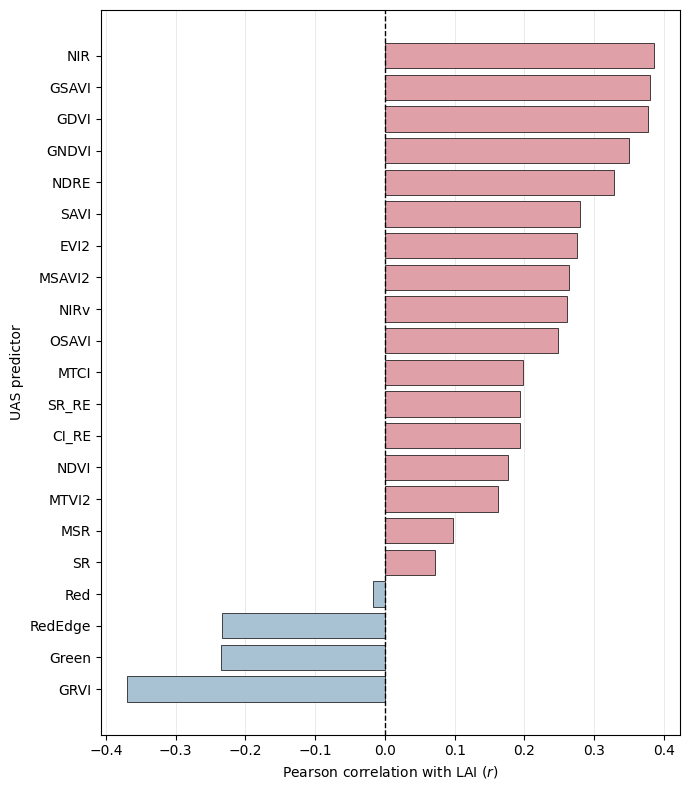

In [6]:
## A4. Plot UAS predictor correlations with field LAI

uas_corr_plot = uas_correlation_table.sort_values("r").copy()
fig, ax = plt.subplots(figsize=(7, 8))
colors = ["#a9c2d3" if r < 0 else "#e0a0a8" for r in uas_corr_plot["r"]]
ax.barh(uas_corr_plot["Predictor"], uas_corr_plot["r"], color=colors, edgecolor="black", linewidth=0.5)
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Pearson correlation with LAI ($r$)"); ax.set_ylabel("UAS predictor")
ax.grid(True, axis="x", color="0.90", linewidth=0.6); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

In [7]:
## B1. Build the strict native UAS–AVIRIS calibration support and extract field HSI spectra

native_records = []
audit_rows = []
for site, uas_path in UAS_FILES.items():
    with rasterio.open(uas_path) as uas_src:
        uas_bounds_polygon = box(uas_src.bounds.left, uas_src.bounds.bottom, uas_src.bounds.right, uas_src.bounds.top)
        site_audit = {'site': site, 'candidate_window_pixels': 0, 'preferred_scene_pixels': 0, 'strict_outer_bounds_pixels': 0, 'full_valid_uas_support_pixels': 0, 'finite_anchor_pixels': 0, 'retained_native_pixels': 0}
        for scene, aviris_path in AVIRIS_L2B.items():
            subdataset = f'NETCDF:{aviris_path}:/reflectance/reflectance'
            with rasterio.open(subdataset) as av_src:
                uas_to_av = Transformer.from_crs(uas_src.crs, av_src.crs, always_xy=True)
                av_to_uas = Transformer.from_crs(av_src.crs, uas_src.crs, always_xy=True)
                uas_bounds_in_av = shapely_transform(uas_to_av.transform, uas_bounds_polygon)
                try:
                    candidate_win = geometry_window(av_src, [mapping(uas_bounds_in_av)], pad_x=1, pad_y=1)
                except WindowError:
                    continue
                row0 = max(0, int(np.floor(candidate_win.row_off)))
                row1 = min(av_src.height, int(np.ceil(candidate_win.row_off + candidate_win.height)))
                col0 = max(0, int(np.floor(candidate_win.col_off)))
                col1 = min(av_src.width, int(np.ceil(candidate_win.col_off + candidate_win.width)))
                for row in range(row0, row1):
                    for col in range(col0, col1):
                        site_audit['candidate_window_pixels'] += 1
                        center_x, center_y = rasterio.transform.xy(av_src.transform, row, col, offset='center')
                        center_x = float(center_x)
                        center_y = float(center_y)
                        if preferred_scene_at_xy(center_x, center_y) != scene:
                            continue
                        site_audit['preferred_scene_pixels'] += 1
                        av_poly = aviris_pixel_polygon(av_src, row, col)
                        uas_poly = shapely_transform(av_to_uas.transform, av_poly)
                        strict_inside_outer_bounds = uas_bounds_polygon.contains(uas_poly) and (not uas_poly.intersects(uas_bounds_polygon.boundary))
                        if not strict_inside_outer_bounds:
                            continue
                        site_audit['strict_outer_bounds_pixels'] += 1
                        agg = aggregate_uas_inside_polygon(uas_src, uas_poly)
                        if agg is None:
                            continue
                        if agg['support_valid_fraction'] < STRICT_INTERIOR_VALID_FRACTION - VALID_TOL or agg['uas_valid_fraction'] < STRICT_INTERIOR_VALID_FRACTION - VALID_TOL:
                            continue
                        site_audit['full_valid_uas_support_pixels'] += 1
                        spectrum = av_src.read(window=Window(col, row, 1, 1)).reshape(av_src.count).astype(float)
                        spectrum[spectrum <= -50] = np.nan
                        check_index = min(100, len(spectrum) - 1)
                        if not np.isfinite(spectrum[check_index]):
                            continue
                        raw_anchors = synthesize_srf_anchors(spectrum)
                        if not np.isfinite(list(raw_anchors.values())).all():
                            continue
                        site_audit['finite_anchor_pixels'] += 1
                        aviris_pixel_id = f'{scene}__{int(row)}_{int(col)}'
                        record = {'aviris_pixel_id': aviris_pixel_id, 'scene': scene, 'row': int(row), 'col': int(col), 'site': site, 'x_m': center_x, 'y_m': center_y, 'footprint_area_m2': float(av_poly.area), 'strict_inside_uas_bounds': True, **agg}
                        for band, value in raw_anchors.items():
                            record[f'Raw_{band}'] = value
                        for band_idx, value in enumerate(spectrum):
                            record[f'band_{band_idx}'] = value
                        native_records.append(record)
                        site_audit['retained_native_pixels'] += 1
        audit_rows.append(site_audit)

calibration_df = pd.DataFrame(native_records).replace([np.inf, -np.inf], np.nan).sort_values(['site', 'scene', 'row', 'col']).reset_index(drop=True)
sampling_audit = pd.DataFrame(audit_rows)
required_calibration_cols = ['UAS_Green', 'UAS_Red', 'UAS_RedEdge', 'UAS_NIR', 'Raw_Green', 'Raw_Red', 'Raw_RedEdge', 'Raw_NIR']
calibration_df = calibration_df.dropna(subset=required_calibration_cols).reset_index(drop=True)
print('============================================================')
print('DIRECT NATIVE-AVIRIS HSI CALIBRATION / BOUNDARY SCREEN')
print('============================================================')
display(sampling_audit)
print(f'\nFinal strict-interior HSI calibration population: n={len(calibration_df)}')
print('\nRetained support by site:')
display(calibration_df.groupby('site').size().rename('n').to_frame())
print('\nRetained support by site and selected scene:')
display(calibration_df.groupby(['site', 'scene']).size().rename('n').to_frame())
print('\nNative footprint area summary (m²):')
display(calibration_df['footprint_area_m2'].describe().to_frame('footprint_area_m2').round(4))
if len(calibration_df) == 0:
    raise RuntimeError('No valid native AVIRIS/UAS calibration pixels were retained.')
if set(calibration_df['site'].unique()) != set(UAS_FILES):
    raise RuntimeError('At least one UAS site has no retained HSI calibration support.')
pixel_site_count = calibration_df.groupby('aviris_pixel_id')['site'].nunique()
if pixel_site_count.max() > 1:
    raise RuntimeError('At least one native AVIRIS pixel is paired with more than one UAS site.')
if calibration_df['aviris_pixel_id'].duplicated().any():
    raise RuntimeError('Duplicate native AVIRIS pixel IDs remain.')
print('Native full-spectrum calibration checks passed.')

spectral_cols = [f'band_{i}' for i in range(len(wavelengths))]
spectra_calibration = calibration_df[spectral_cols].to_numpy(dtype=float)
spectral_range_ok = (wavelengths >= 400.0) & (wavelengths <= 2450.0)
strong_h2o = (wavelengths >= 1340.0) & (wavelengths <= 1450.0) | (wavelengths >= 1800.0) & (wavelengths <= 1980.0)
finite_all_calibration = np.all(np.isfinite(spectra_calibration), axis=0)
nonconstant_calibration = np.nanstd(spectra_calibration, axis=0) > 1e-09
valid_hsi_analysis_mask = spectral_range_ok & ~strong_h2o & finite_all_calibration & nonconstant_calibration
valid_hsi_wavelengths = wavelengths[valid_hsi_analysis_mask]

ANCHOR_X_COLS = ['Raw_Green', 'Raw_Red', 'Raw_RedEdge', 'Raw_NIR']
X_ANCHOR = calibration_df[ANCHOR_X_COLS].to_numpy(dtype=float)
if not np.isfinite(X_ANCHOR).all():
    raise RuntimeError('Non-finite values remain in the four-band SRF anchor predictors.')
if X_ANCHOR.shape[1] != 4:
    raise RuntimeError(f'Expected exactly four anchor predictors; found {X_ANCHOR.shape[1]}.')
print('============================================================')
print('FULL-SPECTRUM QC + FOUR-BAND SRF ANCHOR PREDICTORS')
print('============================================================')
print(f'Total AVIRIS wavelengths retained in stored spectra: {len(wavelengths)}')
print(f'Usable HSI analysis wavelengths after QC: {int(valid_hsi_analysis_mask.sum())}')
print(f'Usable HSI analysis wavelength range: {valid_hsi_wavelengths.min():.1f}–{valid_hsi_wavelengths.max():.1f} nm')
print(f'RF anchor predictor count: {X_ANCHOR.shape[1]}')
print('RF anchor predictors:', ANCHOR_X_COLS)
print('RF configuration:', ANCHOR_RF_KWARGS)

if len(calibration_df) != EXPECTED_STRICT_INTERIOR_N:
    raise RuntimeError(f'Locked final method expects strict-interior n={EXPECTED_STRICT_INTERIOR_N}; found n={len(calibration_df)}. Stop and investigate before using results.')
site_counts_locked = calibration_df.groupby('site').size().rename('n').to_frame()
print('LOCKED strict-interior calibration population confirmed.')
display(site_counts_locked)

def infer_field_source_site(plot_id):
    pid = str(plot_id)
    if pid.startswith('GBS06'):
        return 'BY_2006'
    if pid == 'GBS16N':
        return 'BY_2017_16'
    if pid.startswith('GBS16'):
        return 'BY_2016'
    if pid.startswith('GBS19'):
        return 'BY_2019'
    if pid.startswith('GBS20'):
        return 'BY_2020'
    raise ValueError(f'Unrecognized field plot domain for {plot_id!r}.')

def extract_full_support_from_scene(src, scene, geom):
    rows = []
    cols = []
    spectra = []
    try:
        win = geometry_window(src, [mapping(geom)])
        data = src.read(window=win).astype(float)
        inside = geometry_mask([mapping(geom)], out_shape=(data.shape[1], data.shape[2]), transform=src.window_transform(win), invert=True, all_touched=True)
        check_index = min(100, data.shape[0] - 1)
        check = inside & np.isfinite(data[check_index]) & (data[check_index] > -50)
        rr, cc = np.where(check)
        for r_local, c_local in zip(rr, cc):
            row = int(win.row_off) + int(r_local)
            col = int(win.col_off) + int(c_local)
            spectrum = data[:, r_local, c_local].astype(float)
            spectrum[spectrum <= -50] = np.nan
            if not np.isfinite(spectrum[valid_hsi_analysis_mask]).all():
                continue
            raw_anchors = synthesize_srf_anchors(spectrum)
            if not np.isfinite(list(raw_anchors.values())).all():
                continue
            rows.append(row)
            cols.append(col)
            spectra.append(spectrum)
    except Exception:
        rows = []
        cols = []
        spectra = []
    if len(rows) == 0:
        cx = geom.centroid.x
        cy = geom.centroid.y
        row, col = src.index(cx, cy)
        if not (0 <= row < src.height and 0 <= col < src.width):
            return None
        spectrum = src.read(window=Window(col, row, 1, 1)).reshape(src.count).astype(float)
        spectrum[spectrum <= -50] = np.nan
        if not np.isfinite(spectrum[valid_hsi_analysis_mask]).all():
            return None
        raw_anchors = synthesize_srf_anchors(spectrum)
        if not np.isfinite(list(raw_anchors.values())).all():
            return None
        rows = [int(row)]
        cols = [int(col)]
        spectra = [spectrum]
    xs, ys = rasterio.transform.xy(src.transform, np.asarray(rows, dtype=int), np.asarray(cols, dtype=int), offset='center')
    support_xy = tuple(((float(x), float(y)) for x, y in zip(xs, ys)))
    support_pixel_ids = tuple((f'{scene}__{row}_{col}' for row, col in zip(rows, cols)))
    support_spectra = np.asarray(spectra, dtype=float)
    return {'support_xy': support_xy, 'support_pixel_ids': support_pixel_ids, 'support_spectra': support_spectra, 'pixels_used': len(rows), 'raw_plot_spectrum': np.nanmean(support_spectra, axis=0)}

field_candidates = {pid: [] for pid in lai_gdf['plot_id']}
for scene, path in AVIRIS_L2B.items():
    subdataset = f'NETCDF:{path}:/reflectance/reflectance'
    with rasterio.open(subdataset) as src:
        local = lai_gdf.to_crs(src.crs)
        raster_box = box(src.bounds.left, src.bounds.bottom, src.bounds.right, src.bounds.top)
        img_cx = (src.bounds.left + src.bounds.right) / 2
        img_cy = (src.bounds.bottom + src.bounds.top) / 2
        for rec in local.itertuples(index=False):
            geom = rec.geometry
            if not raster_box.intersects(geom):
                continue
            support = extract_full_support_from_scene(src, scene, geom)
            if support is None:
                continue
            field_candidates[rec.plot_id].append({'scene': scene, 'dist_to_image_center': float(np.hypot(geom.centroid.x - img_cx, geom.centroid.y - img_cy)), **support})

field_records = []
for rec in lai_gdf[['plot_id', 'LAI_mean']].itertuples(index=False):
    options = field_candidates[rec.plot_id]
    if not options:
        continue
    best = min(options, key=lambda d: d['dist_to_image_center'])
    field_records.append({'plot_id': rec.plot_id, 'LAI_mean': float(rec.LAI_mean), 'source_site': infer_field_source_site(rec.plot_id), **best})

field_air_df = pd.DataFrame(field_records).sort_values('plot_id').reset_index(drop=True)
print(f'Field plots with valid full-spectrum AVIRIS data = {len(field_air_df)}')
if len(field_air_df) != EXPECTED_LAI_N:
    raise RuntimeError(f'Expected {EXPECTED_LAI_N} AVIRIS field plots; found {len(field_air_df)}.')
display(field_air_df[['plot_id', 'LAI_mean', 'source_site', 'scene', 'pixels_used', 'dist_to_image_center']])

DIRECT NATIVE-AVIRIS HSI CALIBRATION / BOUNDARY SCREEN


,site,candidate_window_pixels,preferred_scene_pixels,strict_outer_bounds_pixels,full_valid_uas_support_pixels,finite_anchor_pixels,retained_native_pixels
0,BY_2006,3036,995,756,555,555,555
1,BY_2016,2430,810,598,455,455,455
2,BY_2019,1707,754,550,409,409,409
3,BY_2020,2495,625,440,305,287,287
4,BY_2017_16,3078,783,575,441,441,441



Final strict-interior HSI calibration population: n=2147

Retained support by site:


,n
site,
BY_2006,555
BY_2016,455
BY_2017_16,441
BY_2019,409
BY_2020,287



Retained support by site and selected scene:


...

,footprint_area_m2
count,2147.0000
mean,41.4659
std,0.6300
min,40.9600
25%,40.9600
50%,40.9600
75%,42.2500
max,42.2500


Native full-spectrum calibration checks passed.
FULL-SPECTRUM QC + FOUR-BAND SRF ANCHOR PREDICTORS
Total AVIRIS wavelengths retained in stored spectra: 425
Usable HSI analysis wavelengths after QC: 351
Usable HSI analysis wavelength range: 402.2–2445.8 nm
RF anchor predictor count: 4
RF anchor predictors: ['Raw_Green', 'Raw_Red', 'Raw_RedEdge', 'Raw_NIR']
RF configuration: {'n_estimators': 300, 'min_samples_leaf': 10, 'max_features': 4, 'max_depth': 6, 'random_state': 42, 'n_jobs': -1}
LOCKED strict-interior calibration population confirmed.


,n
site,
BY_2006,555
BY_2016,455
BY_2017_16,441
BY_2019,409
BY_2020,287


Field plots with valid full-spectrum AVIRIS data = 20


,plot_id,LAI_mean,source_site,scene,pixels_used,dist_to_image_center
0,GBS0619,2.112576,BY_2006,ang20231031t092656_002,2,2069.789464
1,GBS0622,2.348314,BY_2006,ang20231031t092656_002,1,2032.952380
2,GBS0625,1.575255,BY_2006,ang20231031t092656_002,2,2078.138152
3,GBS0626,1.790895,BY_2006,ang20231031t092656_002,4,2004.185278
4,GBS0627,1.413221,BY_2006,ang20231031t092656_002,4,2000.436585
5,GBS06P,1.977499,BY_2006,ang20231031t092656_002,2,2099.390951
6,GBS161,1.603689,BY_2016,ang20231117t123306_001,4,956.419663
7,GBS162,2.146058,BY_2016,ang20231117t123306_001,2,1105.176524
8,GBS164,1.737210,BY_2016,ang20231117t123306_001,4,955.413203
9,GBS168,1.622965,BY_2016,ang20231117t123306_001,2,1072.729894


In [8]:
## B2. Exclude field support, fit final four-anchor RF models, and adjust the full spectrum

deployment_keep = np.ones(len(calibration_df), dtype=bool)
deployment_exclusion_rows = []
for rec in field_air_df.itertuples(index=False):
    support_xy = np.asarray(rec.support_xy, dtype=float)
    same_scene_idx = np.where(calibration_df['scene'].to_numpy() == rec.scene)[0]
    if len(same_scene_idx) == 0:
        deployment_exclusion_rows.append({'plot_id': rec.plot_id, 'scene': rec.scene, 'n_support_pixels': len(support_xy), 'n_calibration_pixels_excluded': 0})
        continue
    cal_xy = calibration_df.loc[same_scene_idx, ['x_m', 'y_m']].to_numpy(dtype=float)
    tree = cKDTree(support_xy)
    distance, _ = tree.query(cal_xy, k=1, p=np.inf)
    local_excluded_idx = same_scene_idx[distance <= FIELD_BUFFER_M + 1e-09]
    deployment_keep[local_excluded_idx] = False
    deployment_exclusion_rows.append({'plot_id': rec.plot_id, 'scene': rec.scene, 'n_support_pixels': len(support_xy), 'n_calibration_pixels_excluded': len(local_excluded_idx)})
deployment_cal_df = calibration_df.loc[deployment_keep].copy().reset_index(drop=True)

print('============================================================')
print('FINAL HSI DEPLOYMENT CALIBRATION DOMAIN')
print('============================================================')
print(f'Strict-interior calibration before field exclusion: n={len(calibration_df)}')
print(f'After union one-cell field-support exclusion: n={len(deployment_cal_df)}')
print(f'Unique calibration pixels excluded: {int((~deployment_keep).sum())}')
display(pd.DataFrame(deployment_exclusion_rows))
print('\nRemaining deployment support by site:')
display(deployment_cal_df.groupby('site').size().rename('n_train').to_frame())
if set(deployment_cal_df['site'].unique()) != set(calibration_df['site'].unique()):
    raise RuntimeError('Field-support exclusion removed an entire calibration site.')

if len(deployment_cal_df) != EXPECTED_DEPLOY_N:
    raise RuntimeError(f'Locked deployment method expects n={EXPECTED_DEPLOY_N} after field-support exclusion; found n={len(deployment_cal_df)}.')
print(f'LOCKED deployment calibration support confirmed: n={len(deployment_cal_df)}')

X_DEPLOY_ANCHOR = deployment_cal_df[ANCHOR_X_COLS].to_numpy(dtype=float)
if not np.isfinite(X_DEPLOY_ANCHOR).all():
    raise RuntimeError('Non-finite values remain in deployment anchor predictors.')
final_anchor_models = {}
for band, target_col in TARGET_MAP.items():
    y = deployment_cal_df[target_col].to_numpy(dtype=float)
    model = RandomForestRegressor(**ANCHOR_RF_KWARGS)
    model.fit(X_DEPLOY_ANCHOR, y)
    final_anchor_models[band] = model
print(f'Final four-band SRF anchor RFs trained: {list(final_anchor_models)}')

field_harmonized_rows = []
gain_rows = []
for rec in field_air_df.itertuples(index=False):
    support_spectra = np.asarray(rec.support_spectra, dtype=float)
    if support_spectra.ndim != 2 or support_spectra.shape[1] != len(wavelengths):
        raise RuntimeError(f'{rec.plot_id}: malformed support_spectra.')
    harmonized_support = []
    for pixel_i, spectrum in enumerate(support_spectra):
        if not np.isfinite(spectrum[valid_hsi_analysis_mask]).all():
            raise RuntimeError(f'{rec.plot_id}: non-finite field spectrum in the HSI analysis mask.')
        raw_anchors = synthesize_srf_anchors(spectrum)
        raw_anchor_predictors = np.asarray([raw_anchors[band] for band in ANCHOR_BANDS], dtype=float).reshape(1, -1)
        if not np.isfinite(raw_anchor_predictors).all():
            raise RuntimeError(f'{rec.plot_id}: invalid measured-SRF anchor predictor.')
        predicted_anchors = {band: float(model.predict(raw_anchor_predictors)[0]) for band, model in final_anchor_models.items()}
        if not np.isfinite([raw_anchors[band] for band in ANCHOR_BANDS]).all():
            raise RuntimeError(f'{rec.plot_id}: invalid raw SRF anchor.')
        solved = solve_srf_constrained_gain(spectrum, predicted_anchors)
        harmonized_spectrum = solved['harmonized_spectrum']
        knot_gains = solved['knot_gains']
        reconstructed_anchors = solved['reconstructed_anchors']
        harmonized_support.append(harmonized_spectrum)
        gain_rows.append({'plot_id': rec.plot_id, 'scene': rec.scene, 'support_pixel_index': pixel_i, 'KnotGain_Green': knot_gains[0], 'KnotGain_Red': knot_gains[1], 'KnotGain_RedEdge': knot_gains[2], 'KnotGain_NIR': knot_gains[3], 'Pred_Green': predicted_anchors['Green'], 'Pred_Red': predicted_anchors['Red'], 'Pred_RedEdge': predicted_anchors['RedEdge'], 'Pred_NIR': predicted_anchors['NIR'], 'Raw_Green': raw_anchors['Green'], 'Raw_Red': raw_anchors['Red'], 'Raw_RedEdge': raw_anchors['RedEdge'], 'Raw_NIR': raw_anchors['NIR'], 'Recon_Green': reconstructed_anchors['Green'], 'Recon_Red': reconstructed_anchors['Red'], 'Recon_RedEdge': reconstructed_anchors['RedEdge'], 'Recon_NIR': reconstructed_anchors['NIR'], 'Max_abs_anchor_residual': solved['max_abs_anchor_residual'], 'Gain_system_condition_number': solved['condition_number'], 'Gain_solver': solved['solver'], 'Min_gain_curve': float(np.nanmin(solved['gain_curve'])), 'Max_gain_curve': float(np.nanmax(solved['gain_curve']))})
    harmonized_support = np.asarray(harmonized_support, dtype=float)
    raw_plot_spectrum = np.nanmean(support_spectra, axis=0)
    harmonized_plot_spectrum = np.nanmean(harmonized_support, axis=0)
    field_harmonized_rows.append({'plot_id': rec.plot_id, 'LAI_mean': rec.LAI_mean, 'source_site': rec.source_site, 'scene': rec.scene, 'pixels_used': rec.pixels_used, 'raw_spectrum': raw_plot_spectrum, 'harmonized_spectrum': harmonized_plot_spectrum})

field_harmonized_df = pd.DataFrame(field_harmonized_rows).sort_values('plot_id').reset_index(drop=True)
field_gain_df = pd.DataFrame(gain_rows)
print(f'Field plots harmonized = {len(field_harmonized_df)}')
print('\n============================================================')
print('SRF-CONSTRAINED ANCHOR CLOSURE AUDIT')
print('============================================================')
closure_cols = ['Max_abs_anchor_residual', 'Gain_system_condition_number', 'Min_gain_curve', 'Max_gain_curve']
display(field_gain_df[closure_cols].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(8))
max_closure_error = float(field_gain_df['Max_abs_anchor_residual'].max())
print(f'\nMaximum absolute SRF-anchor closure error = {max_closure_error:.12g}')
print('Gain solvers used:')
display(field_gain_df['Gain_solver'].value_counts().rename('n').to_frame())
nonpositive_gain_pixels = int((field_gain_df['Min_gain_curve'] <= 0).sum())
print(f'Field support pixels with any non-positive gain = {nonpositive_gain_pixels}')
if max_closure_error > 1e-08:
    print('WARNING: SRF closure is not at numerical precision; inspect gain-system conditioning.')
if nonpositive_gain_pixels > 0:
    print('WARNING: at least one solved spectral gain curve becomes non-positive. Inspect those support pixels before interpretation.')
print('\nGain-knot summary:')
display(field_gain_df[['KnotGain_Green', 'KnotGain_Red', 'KnotGain_RedEdge', 'KnotGain_NIR']].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(4))
print('\nPlot-level support:')
display(field_harmonized_df[['plot_id', 'LAI_mean', 'source_site', 'scene', 'pixels_used']])

FINAL HSI DEPLOYMENT CALIBRATION DOMAIN
Strict-interior calibration before field exclusion: n=2147
After union one-cell field-support exclusion: n=2006
Unique calibration pixels excluded: 141


,plot_id,scene,n_support_pixels,n_calibration_pixels_excluded
0,GBS0619,ang20231031t092656_002,2,12
1,GBS0622,ang20231031t092656_002,1,9
2,GBS0625,ang20231031t092656_002,2,12
3,GBS0626,ang20231031t092656_002,4,8
4,GBS0627,ang20231031t092656_002,4,16
5,GBS06P,ang20231031t092656_002,2,12
6,GBS161,ang20231117t123306_001,4,0
7,GBS162,ang20231117t123306_001,2,0
8,GBS164,ang20231117t123306_001,4,16
9,GBS168,ang20231117t123306_001,2,3



Remaining deployment support by site:


,n_train
site,
BY_2006,486
BY_2016,423
BY_2017_16,429
BY_2019,393
BY_2020,275


LOCKED deployment calibration support confirmed: n=2006
Final four-band SRF anchor RFs trained: ['Green', 'Red', 'RedEdge', 'NIR']
Field plots harmonized = 20

SRF-CONSTRAINED ANCHOR CLOSURE AUDIT


...

,n
Gain_solver,
solve,54


Field support pixels with any non-positive gain = 0

Gain-knot summary:


,KnotGain_Green,KnotGain_Red,KnotGain_RedEdge,KnotGain_NIR
count,54.0000,54.0000,54.0000,54.0000
mean,0.6679,0.6072,0.6083,1.0256
std,0.0571,0.0307,0.0665,0.0780
min,0.5425,0.5365,0.4642,0.9097
5%,0.5799,0.5512,0.5033,0.9139
25%,0.6179,0.5919,0.5567,0.9459
50%,0.6865,0.6144,0.6235,1.0304
75%,0.7095,0.6329,0.6500,1.0888
95%,0.7423,0.6445,0.7200,1.1373
max,0.7588,0.6492,0.7494,1.1598



Plot-level support:


,plot_id,LAI_mean,source_site,scene,pixels_used
0,GBS0619,2.112576,BY_2006,ang20231031t092656_002,2
1,GBS0622,2.348314,BY_2006,ang20231031t092656_002,1
2,GBS0625,1.575255,BY_2006,ang20231031t092656_002,2
3,GBS0626,1.790895,BY_2006,ang20231031t092656_002,4
4,GBS0627,1.413221,BY_2006,ang20231031t092656_002,4
5,GBS06P,1.977499,BY_2006,ang20231031t092656_002,2
6,GBS161,1.603689,BY_2016,ang20231117t123306_001,4
7,GBS162,2.146058,BY_2016,ang20231117t123306_001,2
8,GBS164,1.737210,BY_2016,ang20231117t123306_001,4
9,GBS168,1.622965,BY_2016,ang20231117t123306_001,2


In [9]:
## B3. Build raw/adjusted HSI representations and the common n=11 sample

raw_spectra_n20 = np.vstack(field_harmonized_df['raw_spectrum'].to_numpy())
harm_spectra_n20 = np.vstack(field_harmonized_df['harmonized_spectrum'].to_numpy())
raw_hsi_indices_n20 = calculate_hsi_indices(raw_spectra_n20, wavelengths)
harm_hsi_indices_n20 = calculate_hsi_indices(harm_spectra_n20, wavelengths)
raw_srf_bands_n20 = synthesize_srf_anchor_matrix(raw_spectra_n20)
harm_srf_bands_n20 = synthesize_srf_anchor_matrix(harm_spectra_n20)
raw_srf_msi_indices_n20 = calculate_uas_indices(raw_srf_bands_n20['Green'], raw_srf_bands_n20['Red'], raw_srf_bands_n20['RedEdge'], raw_srf_bands_n20['NIR'])
harm_srf_msi_indices_n20 = calculate_uas_indices(harm_srf_bands_n20['Green'], harm_srf_bands_n20['Red'], harm_srf_bands_n20['RedEdge'], harm_srf_bands_n20['NIR'])
y_n20 = field_harmonized_df['LAI_mean'].to_numpy(dtype=float)
plot_ids_n20 = field_harmonized_df['plot_id'].astype(str).to_numpy()
print(f'Native HSI n=20 representations: {len(raw_hsi_indices_n20)} raw indices and {len(harm_hsi_indices_n20)} harmonized indices.')
print(f'SRF-MSI bridge representations: {len(raw_srf_msi_indices_n20)} raw indices and {len(harm_srf_msi_indices_n20)} harmonized indices.')
pred_anchor_means = field_gain_df.groupby('plot_id', as_index=True)[['Pred_Green', 'Pred_Red', 'Pred_RedEdge', 'Pred_NIR']].mean()

plot_closure_rows = []
for i, pid in enumerate(plot_ids_n20):
    pid = str(pid)
    row = {'plot_id': pid}
    for band in ANCHOR_BANDS:
        predicted_mean = float(pred_anchor_means.loc[pid, f'Pred_{band}'])
        reconstructed_plot = float(harm_srf_bands_n20[band][i])
        row[f'Residual_{band}'] = reconstructed_plot - predicted_mean
    row['Max_abs_plot_anchor_residual'] = max((abs(row[f'Residual_{band}']) for band in ANCHOR_BANDS))
    plot_closure_rows.append(row)
plot_srf_closure = pd.DataFrame(plot_closure_rows)
print('\nPlot-level SRF closure:')
display(plot_srf_closure.round(10))
print(f"\nMaximum plot-level SRF closure error = {plot_srf_closure['Max_abs_plot_anchor_residual'].max():.12g}")

common_n11 = uas_plot_df.merge(field_harmonized_df[['plot_id', 'LAI_mean', 'source_site', 'scene', 'pixels_used']], on='plot_id', how='inner', validate='one_to_one', suffixes=('_UAS', '_HSI')).sort_values('plot_id').reset_index(drop=True)
if not np.allclose(common_n11['LAI_mean_UAS'].to_numpy(dtype=float), common_n11['LAI_mean_HSI'].to_numpy(dtype=float), rtol=0, atol=1e-12):
    raise RuntimeError('LAI values differ between UAS and HSI field tables.')
common_n11['LAI_mean'] = common_n11['LAI_mean_UAS'].astype(float)
if len(common_n11) != EXPECTED_COMMON_UAS_N:
    raise RuntimeError(f'Expected common n={EXPECTED_COMMON_UAS_N}; found {len(common_n11)}.')
field_lookup = {pid: i for i, pid in enumerate(field_harmonized_df['plot_id'].astype(str))}
common_pos = np.array([field_lookup[str(pid)] for pid in common_n11['plot_id']], dtype=int)
uas_indices_n11 = calculate_uas_indices(common_n11['UAS_Green'], common_n11['UAS_Red'], common_n11['UAS_RedEdge'], common_n11['UAS_NIR'])
raw_hsi_indices_n11 = calculate_hsi_indices(raw_spectra_n20[common_pos], wavelengths)
harm_hsi_indices_n11 = calculate_hsi_indices(harm_spectra_n20[common_pos], wavelengths)
raw_srf_msi_indices_n11 = {name: np.asarray(values, dtype=float)[common_pos] for name, values in raw_srf_msi_indices_n20.items()}
harm_srf_msi_indices_n11 = {name: np.asarray(values, dtype=float)[common_pos] for name, values in harm_srf_msi_indices_n20.items()}
y_n11 = common_n11['LAI_mean'].to_numpy(dtype=float)
print('Common UAS + HSI plots:')
display(common_n11[['plot_id', 'LAI_mean', 'source_site_UAS', 'source_site_HSI', 'scene', 'pixels_used']])

Native HSI n=20 representations: 28 raw indices and 28 harmonized indices.
SRF-MSI bridge representations: 17 raw indices and 17 harmonized indices.

Plot-level SRF closure:


,plot_id,Residual_Green,Residual_Red,Residual_RedEdge,Residual_NIR,Max_abs_plot_anchor_residual
0,GBS0619,0.0,0.0,-0.0,0.0,0.0
1,GBS0622,0.0,-0.0,0.0,0.0,0.0
2,GBS0625,-0.0,-0.0,0.0,0.0,0.0
3,GBS0626,0.0,0.0,-0.0,-0.0,0.0
4,GBS0627,0.0,0.0,0.0,0.0,0.0
5,GBS06P,-0.0,0.0,0.0,0.0,0.0
6,GBS161,0.0,0.0,0.0,0.0,0.0
7,GBS162,-0.0,0.0,0.0,0.0,0.0
8,GBS164,0.0,0.0,0.0,-0.0,0.0
9,GBS168,0.0,0.0,0.0,0.0,0.0



Maximum plot-level SRF closure error = 5.55111512313e-17
Common UAS + HSI plots:


,plot_id,LAI_mean,source_site_UAS,source_site_HSI,scene,pixels_used
0,GBS0619,2.112576,BY_2006,BY_2006,ang20231031t092656_002,2
1,GBS0622,2.348314,BY_2006,BY_2006,ang20231031t092656_002,1
2,GBS0625,1.575255,BY_2006,BY_2006,ang20231031t092656_002,2
3,GBS0626,1.790895,BY_2006,BY_2006,ang20231031t092656_002,4
4,GBS0627,1.413221,BY_2006,BY_2006,ang20231031t092656_002,4
5,GBS06P,1.977499,BY_2006,BY_2006,ang20231031t092656_002,2
6,GBS164,1.737210,BY_2016,BY_2016,ang20231117t123306_001,4
7,GBS16N,1.415269,BY_2017_16,BY_2017_16,ang20231117t123306_001,1
8,GBS16P,0.704166,BY_2016,BY_2016,ang20231117t123306_001,4
9,GBS19P,1.133654,BY_2019,BY_2019,ang20231117t123306_001,4


In [10]:
## B4. Compare raw and UAS-guided adjusted HSI relationships

def screen_single_index_models(representation_dict, y):
    rows = []
    prediction_store = {}
    for representation, index_dict in representation_dict.items():
        for index_name, values in index_dict.items():
            for form in ['Linear', 'Quadratic']:
                result = evaluate_single_index(values, y, form)
                rows.append({'Representation': representation, 'Index': index_name, 'Form': form, 'n': result['n'], 'Full_R2': result['Full_R2'], 'Full_RMSE': result['Full_RMSE'], 'LOOCV_R2': result['LOOCV_R2'], 'LOOCV_RMSE': result['LOOCV_RMSE'], 'LOOCV_MAE': result['LOOCV_MAE']})
                prediction_store[representation, index_name, form] = result
    results = pd.DataFrame(rows)
    best_rows = []
    for representation in representation_dict:
        best = results[results['Representation'] == representation].sort_values(['LOOCV_R2', 'LOOCV_RMSE'], ascending=[False, True]).iloc[0]
        best_rows.append(best.to_dict())
    return (results, pd.DataFrame(best_rows), prediction_store)

representations_n20 = {'Raw HSI': raw_hsi_indices_n20, 'Harmonized HSI': harm_hsi_indices_n20}
hsi_single_results_n20, hsi_single_best_n20, hsi_single_prediction_store_n20 = screen_single_index_models(representations_n20, y_n20)
print('============================================================')
print('PRIMARY n=20 HSI SINGLE-INDEX LAI COMPARISON')
print('============================================================')
display(hsi_single_best_n20[['Representation', 'Index', 'Form', 'n', 'Full_R2', 'Full_RMSE', 'LOOCV_R2', 'LOOCV_RMSE', 'LOOCV_MAE']].round(3))
for representation in representations_n20:
    print('\n' + '=' * 72)
    print(f'TOP n=20 HSI MODELS: {representation}')
    print('=' * 72)
    display(hsi_single_results_n20[hsi_single_results_n20['Representation'] == representation].sort_values(['LOOCV_R2', 'LOOCV_RMSE'], ascending=[False, True])[['Index', 'Form', 'Full_R2', 'Full_RMSE', 'LOOCV_R2', 'LOOCV_RMSE', 'LOOCV_MAE']].head(12).reset_index(drop=True).round(3))

hsi_corr_rows = []
for representation, index_dict in [('Raw HSI', raw_hsi_indices_n20), ('Harmonized HSI', harm_hsi_indices_n20)]:
    for index_name, values in index_dict.items():
        x = np.asarray(values, float)
        valid = np.isfinite(x) & np.isfinite(y_n20)
        if valid.sum() < 3 or np.std(x[valid]) == 0:
            r, p = (np.nan, np.nan)
        else:
            r, p = pearsonr(x[valid], y_n20[valid])
        hsi_corr_rows.append({'Representation': representation, 'Index': index_name, 'n': int(valid.sum()), 'r': r, 'p': p})

hsi_correlation_table = pd.DataFrame(hsi_corr_rows)
hsi_correlation_table['abs_r'] = hsi_correlation_table['r'].abs()
print('HSI index correlations with effective LAI (descriptive; unadjusted p values):')
display(hsi_correlation_table.sort_values(['Representation', 'abs_r'], ascending=[True, False]).drop(columns='abs_r').round(4))

raw_single = hsi_single_results_n20[hsi_single_results_n20['Representation'] == 'Raw HSI'].copy()
harm_single = hsi_single_results_n20[hsi_single_results_n20['Representation'] == 'Harmonized HSI'].copy()
matched_single_n20 = raw_single[['Index', 'Form', 'LOOCV_R2', 'LOOCV_RMSE']].rename(columns={'LOOCV_R2': 'Raw_R2', 'LOOCV_RMSE': 'Raw_RMSE'}).merge(harm_single[['Index', 'Form', 'LOOCV_R2', 'LOOCV_RMSE']].rename(columns={'LOOCV_R2': 'Harm_R2', 'LOOCV_RMSE': 'Harm_RMSE'}), on=['Index', 'Form'], how='inner', validate='one_to_one')
matched_single_n20['Delta_R2'] = matched_single_n20['Harm_R2'] - matched_single_n20['Raw_R2']
matched_single_n20['RMSE_reduction'] = matched_single_n20['Raw_RMSE'] - matched_single_n20['Harm_RMSE']
print('Matched HSI n=20 harmonization effects (same index and same regression form):')
display(matched_single_n20.sort_values('Delta_R2', ascending=False).reset_index(drop=True).round(3))
print('\nFixed Custom_SWIR_Primary (Linear) comparison:')
display(matched_single_n20[(matched_single_n20['Index'] == 'Custom_SWIR_Primary') & (matched_single_n20['Form'] == 'Linear')].round(3))

uas_results_n11, uas_best_n11, uas_prediction_store_n11 = screen_single_index_models({'UAS': uas_indices_n11}, y_n11)
hsi_results_n11, hsi_best_n11, hsi_prediction_store_n11 = screen_single_index_models({'Raw native HSI': raw_hsi_indices_n11, 'Harmonized native HSI': harm_hsi_indices_n11}, y_n11)
common_best_summary = pd.concat([uas_best_n11, hsi_best_n11], ignore_index=True)
print('============================================================')
print('COMMON n=11 UAS / NATIVE-HSI COMPARISON')
print('============================================================')
display(common_best_summary[['Representation', 'Index', 'Form', 'n', 'Full_R2', 'Full_RMSE', 'LOOCV_R2', 'LOOCV_RMSE', 'LOOCV_MAE']].round(3))
srf_bridge_results_n11, srf_bridge_best_n11, srf_bridge_prediction_store_n11 = screen_single_index_models({'Raw HSI -> Mavic SRF MSI': raw_srf_msi_indices_n11, 'Harmonized HSI -> Mavic SRF MSI': harm_srf_msi_indices_n11}, y_n11)
print('\n============================================================')
print('COMMON n=11 MAVIC-SRF MSI BRIDGE')
print('============================================================')
display(pd.concat([uas_best_n11, srf_bridge_best_n11], ignore_index=True)[['Representation', 'Index', 'Form', 'n', 'Full_R2', 'Full_RMSE', 'LOOCV_R2', 'LOOCV_RMSE', 'LOOCV_MAE']].round(3))
uas_best_row = uas_best_n11.iloc[0]
fixed_uas_index = str(uas_best_row['Index'])
fixed_uas_form = str(uas_best_row['Form'])
uas_fixed = uas_results_n11[(uas_results_n11['Index'] == fixed_uas_index) & (uas_results_n11['Form'] == fixed_uas_form)].iloc[0]
fixed_srf_rows = [uas_fixed.to_dict()]
for representation in ['Raw HSI -> Mavic SRF MSI', 'Harmonized HSI -> Mavic SRF MSI']:
    row = srf_bridge_results_n11[(srf_bridge_results_n11['Representation'] == representation) & (srf_bridge_results_n11['Index'] == fixed_uas_index) & (srf_bridge_results_n11['Form'] == fixed_uas_form)].iloc[0]
    fixed_srf_rows.append(row.to_dict())
fixed_uas_srf_transfer_n11 = pd.DataFrame(fixed_srf_rows)
print(f'\nFixed same-index/same-form Mavic-SRF comparison: {fixed_uas_index} ({fixed_uas_form})')
display(fixed_uas_srf_transfer_n11[['Representation', 'Index', 'Form', 'n', 'LOOCV_R2', 'LOOCV_RMSE', 'LOOCV_MAE']].round(3))
if fixed_uas_index in HSI_INDEX_NAMES:
    native_fixed_rows = [uas_fixed.to_dict()]
    for representation in ['Raw native HSI', 'Harmonized native HSI']:
        row = hsi_results_n11[(hsi_results_n11['Representation'] == representation) & (hsi_results_n11['Index'] == fixed_uas_index) & (hsi_results_n11['Form'] == fixed_uas_form)].iloc[0]
        native_fixed_rows.append(row.to_dict())
    fixed_native_hsi_transfer_n11 = pd.DataFrame(native_fixed_rows)
    print(f'\nSecondary narrowband-HSI comparison for {fixed_uas_index} ({fixed_uas_form})')
    print('This is NOT an identical sensor-response comparison: native HSI uses discrete AVIRIS wavelengths.')
    display(fixed_native_hsi_transfer_n11[['Representation', 'Index', 'Form', 'n', 'LOOCV_R2', 'LOOCV_RMSE', 'LOOCV_MAE']].round(3))

PRIMARY n=20 HSI SINGLE-INDEX LAI COMPARISON


,Representation,Index,Form,n,Full_R2,Full_RMSE,LOOCV_R2,LOOCV_RMSE,LOOCV_MAE
0,Raw HSI,Custom_SWIR_Primary,Linear,20,0.522,0.355,0.427,0.388,0.316
1,Harmonized HSI,Custom_SWIR_Primary,Linear,20,0.518,0.356,0.423,0.390,0.319



TOP n=20 HSI MODELS: Raw HSI


,Index,Form,Full_R2,Full_RMSE,LOOCV_R2,LOOCV_RMSE,LOOCV_MAE
0,Custom_SWIR_Primary,Linear,0.522,0.355,0.427,0.388,0.316
1,Custom_SWIR_Primary,Quadratic,0.525,0.354,0.302,0.429,0.348
2,Custom_SWIR1_Bridge,Quadratic,0.409,0.395,0.291,0.432,0.310
3,Custom_NIR_Plateau,Linear,0.377,0.405,0.241,0.447,0.333
4,Custom_SWIR1_Bridge,Linear,0.355,0.412,0.231,0.450,0.329
5,Custom_NIR_Plateau,Quadratic,0.387,0.402,0.214,0.455,0.345
6,Custom_VIS_Green,Linear,0.365,0.409,0.207,0.457,0.390
7,CAI,Linear,0.448,0.381,0.166,0.469,0.355
8,NDLI,Quadratic,0.288,0.433,0.083,0.491,0.362
9,NDLI,Linear,0.256,0.443,0.068,0.496,0.358



TOP n=20 HSI MODELS: Harmonized HSI


...

,Representation,Index,Form,n,Full_R2,Full_RMSE,LOOCV_R2,LOOCV_RMSE,LOOCV_MAE
0,UAS,GDVI,Quadratic,11,0.620,0.286,0.444,0.346,0.283
1,Raw HSI -> Mavic SRF MSI,GRVI,Quadratic,11,0.672,0.266,0.429,0.351,0.319
2,Harmonized HSI -> Mavic SRF MSI,GSAVI,Linear,11,0.801,0.207,0.713,0.249,0.226



Fixed same-index/same-form Mavic-SRF comparison: GDVI (Quadratic)


,Representation,Index,Form,n,LOOCV_R2,LOOCV_RMSE,LOOCV_MAE
0,UAS,GDVI,Quadratic,11,0.444,0.346,0.283
1,Raw HSI -> Mavic SRF MSI,GDVI,Quadratic,11,0.249,0.402,0.372
2,Harmonized HSI -> Mavic SRF MSI,GDVI,Quadratic,11,0.562,0.307,0.290



Secondary narrowband-HSI comparison for GDVI (Quadratic)
This is NOT an identical sensor-response comparison: native HSI uses discrete AVIRIS wavelengths.


,Representation,Index,Form,n,LOOCV_R2,LOOCV_RMSE,LOOCV_MAE
0,UAS,GDVI,Quadratic,11,0.444,0.346,0.283
1,Raw native HSI,GDVI,Quadratic,11,0.295,0.390,0.353
2,Harmonized native HSI,GDVI,Quadratic,11,0.571,0.304,0.285


Representative plot: GBS161; LAI = 1.604
Generating representative before/after spectral comparison plot...


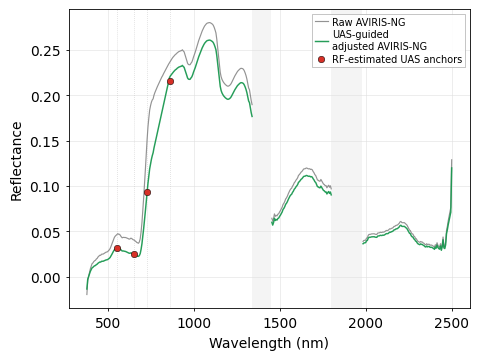


COMMON n=11 UAS / FULL-SPECTRUM HSI CONTEXT — DESCRIPTIVE


,Representation,Predictor,Form,n,LOOCV_R2,LOOCV_RMSE,LOOCV_MAE
0,UAS,GDVI,Quadratic,11,0.444,0.346,0.283
1,Raw AVIRIS-NG,Custom_SWIR_Primary,Linear,11,0.688,0.259,0.209
2,UAS-guided adjusted AVIRIS-NG,Custom_SWIR_Primary,Linear,11,0.683,0.261,0.210


In [11]:
## B5. Representative UAS-guided full-spectrum adjustment

median_lai = float(np.median(y_n20))
representative_pos = int(np.argmin(np.abs(y_n20 - median_lai)))
representative_id = str(plot_ids_n20[representative_pos])
representative_lai = float(y_n20[representative_pos])
print(f'Representative plot: {representative_id}; LAI = {representative_lai:.3f}')
print('Generating representative before/after spectral comparison plot...')
plot_orig = np.array(raw_spectra_n20[representative_pos], dtype=float, copy=True)
plot_adjusted = np.array(harm_spectra_n20[representative_pos], dtype=float, copy=True)
water_bands = (wavelengths >= 1340) & (wavelengths <= 1450) | (wavelengths >= 1800) & (wavelengths <= 1980)
plot_orig[water_bands] = np.nan
plot_adjusted[water_bands] = np.nan
rep_gain_rows = field_gain_df[field_gain_df['plot_id'].astype(str) == str(representative_id)].copy()
if rep_gain_rows.empty:
    raise RuntimeError(f'No gain/anchor records found for representative plot {representative_id}.')
anchor_wls = np.asarray(ANCHOR_WAVELENGTHS, dtype=float)
uas_anchor_values = np.asarray([rep_gain_rows['Pred_Green'].mean(), rep_gain_rows['Pred_Red'].mean(), rep_gain_rows['Pred_RedEdge'].mean(), rep_gain_rows['Pred_NIR'].mean()], dtype=float)
fig, ax = plt.subplots(figsize=(4.9, 3.71))
for water_start, water_end in [(1340, 1450), (1800, 1980)]:
    ax.axvspan(water_start, water_end, color='0.92', linewidth=0, alpha=0.55, zorder=0)
for wl in anchor_wls:
    ax.axvline(wl, color='0.72', linestyle=':', linewidth=0.55, alpha=0.6, zorder=1)
ax.plot(wavelengths, plot_orig, color='0.50', linewidth=0.85, alpha=0.85, label='Raw AVIRIS-NG', zorder=3)
ax.plot(wavelengths, plot_adjusted, color='#1a9850', linewidth=1.05, alpha=0.95, label='UAS-guided\nadjusted AVIRIS-NG', zorder=4)
ax.scatter(anchor_wls, uas_anchor_values, color='#d73027', edgecolor='black', linewidth=0.35, marker='o', s=22, zorder=5, label='RF-estimated UAS anchors')
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Reflectance')
ax.grid(True, color='0.88', linewidth=0.4)
ax.set_axisbelow(True)
ax.tick_params(axis='both', length=2.5, width=0.6)
for spine in ax.spines.values():
    spine.set_linewidth(0.6)
leg = ax.legend(loc='upper right', frameon=True, fancybox=False, edgecolor='0.65', facecolor='white', framealpha=0.9, fontsize=7, borderpad=0.28, handlelength=1.4, handletextpad=0.4, labelspacing=0.3)
leg.get_frame().set_linewidth(0.5)
fig.tight_layout()
plt.show()
uas_gdvi_n11 = uas_results_n11[(uas_results_n11['Index'] == 'GDVI') & (uas_results_n11['Form'] == 'Quadratic')].iloc[0]
raw_swir_n11 = evaluate_single_index(raw_hsi_indices_n11[PRIMARY_HSI_INDEX], y_n11, PRIMARY_HSI_FORM)
adjusted_swir_n11 = evaluate_single_index(harm_hsi_indices_n11[PRIMARY_HSI_INDEX], y_n11, PRIMARY_HSI_FORM)
common_n11_hsi_context = pd.DataFrame([{'Representation': 'UAS', 'Predictor': 'GDVI', 'Form': 'Quadratic', 'n': int(uas_gdvi_n11['n']), 'LOOCV_R2': uas_gdvi_n11['LOOCV_R2'], 'LOOCV_RMSE': uas_gdvi_n11['LOOCV_RMSE'], 'LOOCV_MAE': uas_gdvi_n11['LOOCV_MAE']}, {'Representation': 'Raw AVIRIS-NG', 'Predictor': PRIMARY_HSI_INDEX, 'Form': PRIMARY_HSI_FORM, 'n': raw_swir_n11['n'], 'LOOCV_R2': raw_swir_n11['LOOCV_R2'], 'LOOCV_RMSE': raw_swir_n11['LOOCV_RMSE'], 'LOOCV_MAE': raw_swir_n11['LOOCV_MAE']}, {'Representation': 'UAS-guided adjusted AVIRIS-NG', 'Predictor': PRIMARY_HSI_INDEX, 'Form': PRIMARY_HSI_FORM, 'n': adjusted_swir_n11['n'], 'LOOCV_R2': adjusted_swir_n11['LOOCV_R2'], 'LOOCV_RMSE': adjusted_swir_n11['LOOCV_RMSE'], 'LOOCV_MAE': adjusted_swir_n11['LOOCV_MAE']}])
print('\n' + '=' * 72)
print('COMMON n=11 UAS / FULL-SPECTRUM HSI CONTEXT — DESCRIPTIVE')
print('=' * 72)
display(common_n11_hsi_context.round(3))

In [12]:
## C1. Apply the fixed raw Custom_SWIR_Primary model across the landscape

MAPPING_INDEX = 'Custom_SWIR_Primary'
mapping_x = np.asarray(raw_hsi_indices_n20[MAPPING_INDEX], dtype=float)
mapping_y = np.asarray(y_n20, dtype=float)
valid_fit = np.isfinite(mapping_x) & np.isfinite(mapping_y)
final_landscape_model = LinearRegression()
final_landscape_model.fit(mapping_x[valid_fit].reshape(-1, 1), mapping_y[valid_fit])
field_index_min = float(np.min(mapping_x[valid_fit]))
field_index_max = float(np.max(mapping_x[valid_fit]))
field_lai_min = float(np.min(mapping_y[valid_fit]))
field_lai_max = float(np.max(mapping_y[valid_fit]))

print('============================================================')
print('FINAL CUSTOM_SWIR_PRIMARY LANDSCAPE MODEL')
print('============================================================')
print(f'LAI = {final_landscape_model.intercept_:.6f} + {final_landscape_model.coef_[0]:.6f} * Custom_SWIR_Primary')
print(f'\nField Custom_SWIR_Primary range: {field_index_min:.5f} to {field_index_max:.5f}')
print(f'Observed field LAI range: {field_lai_min:.3f} to {field_lai_max:.3f}')
idx_2005 = int(np.argmin(np.abs(np.asarray(wavelengths, dtype=float) - 2005.0)))
idx_2320 = int(np.argmin(np.abs(np.asarray(wavelengths, dtype=float) - 2320.5)))
wl_2005 = float(wavelengths[idx_2005])
wl_2320 = float(wavelengths[idx_2320])
print('\nActual AVIRIS-NG wavelengths used:')
print(f'2005-nm target   -> {wl_2005:.2f} nm')
print(f'2320.5-nm target -> {wl_2320:.2f} nm')

fire_shape_candidates = [Path('../Fire_boundaries_shapes/fire_region_new_CRS.shp'), Path('./Fire_boundaries_shapes/fire_region_new_CRS.shp')]
fire_shape_path = next((path for path in fire_shape_candidates if path.exists()), None)
if fire_shape_path is None:
    raise FileNotFoundError('Could not locate fire_region_new_CRS.shp.\nChecked:\n' + '\n'.join((str(path) for path in fire_shape_candidates)))
fire_gdf_original = gpd.read_file(fire_shape_path).copy()
if 'Year' not in fire_gdf_original.columns:
    raise KeyError("Fire shapefile must contain a 'Year' column.")
fire_gdf_original['Year'] = fire_gdf_original['Year'].astype(int)
fire_gdf_original['fire_polygon_id'] = np.arange(len(fire_gdf_original))
print(f'\nFire polygons loaded: {len(fire_gdf_original)}')

memory_files = []
memory_datasets = []
scene_prediction_summary = []
EPS_LANDSCAPE = 1e-10
for scene, nc_path in AVIRIS_L2B.items():
    print(f'\nProcessing {scene} ...')
    subdataset = f'NETCDF:{nc_path}:/reflectance/reflectance'
    with rasterio.open(subdataset) as src:
        r2005 = src.read(idx_2005 + 1).astype(float)
        r2320 = src.read(idx_2320 + 1).astype(float)
        mask2005 = src.read_masks(idx_2005 + 1) > 0
        mask2320 = src.read_masks(idx_2320 + 1) > 0
        valid = mask2005 & mask2320 & np.isfinite(r2005) & np.isfinite(r2320) & (r2005 > -50) & (r2320 > -50)
        if src.nodata is not None:
            valid &= (r2005 != src.nodata) & (r2320 != src.nodata)
        denominator = r2320 + r2005
        valid &= np.isfinite(denominator) & (np.abs(denominator) > EPS_LANDSCAPE)
        swir_index = np.full(r2005.shape, np.nan, dtype=float)
        swir_index[valid] = (r2320[valid] - r2005[valid]) / (r2320[valid] + r2005[valid] + EPS_LANDSCAPE)
        predicted_lai = np.full(swir_index.shape, np.nan, dtype=float)
        prediction_valid = np.isfinite(swir_index)
        predicted_lai[prediction_valid] = final_landscape_model.predict(swir_index[prediction_valid].reshape(-1, 1))
        outside_index_domain = prediction_valid & ((swir_index < field_index_min) | (swir_index > field_index_max))
        n_valid = int(prediction_valid.sum())
        scene_prediction_summary.append({'scene': scene, 'valid_pixels': n_valid, 'fraction_index_outside_field_range': float(outside_index_domain.sum() / n_valid) if n_valid > 0 else np.nan, 'predicted_LAI_mean': float(np.nanmean(predicted_lai)) if n_valid > 0 else np.nan})
        output_array = np.where(prediction_valid, predicted_lai, -9999.0).astype('float32')
        profile = src.profile.copy()
        profile.update(driver='GTiff', count=1, dtype='float32', nodata=-9999.0)
        memfile = MemoryFile()
        memds = memfile.open(**profile)
        memds.write(output_array, 1)
        memory_files.append(memfile)
        memory_datasets.append(memds)

scene_prediction_summary = pd.DataFrame(scene_prediction_summary)
print('\nLANDSCAPE PREDICTION DIAGNOSTICS')
display(scene_prediction_summary.round(4))
if len(memory_datasets) == 0:
    raise RuntimeError('No valid AVIRIS-NG prediction rasters were created.')
mosaic, mosaic_transform = merge(memory_datasets, nodata=-9999.0, method='first')
mosaic_crs = memory_datasets[0].crs
mosaic_lai = mosaic[0].astype(float)
mosaic_valid = np.isfinite(mosaic_lai) & (mosaic_lai != -9999.0)
mosaic_lai_unclipped = np.where(mosaic_valid, mosaic_lai, np.nan)

print(f'\nMosaic valid pixels: {int(mosaic_valid.sum()):,}')
fig_dir = Path('images/Revision')
fig_dir.mkdir(parents=True, exist_ok=True)
raster_out_dir = fig_dir / 'Predicted_LAI_Rasters'
raster_out_dir.mkdir(parents=True, exist_ok=True)
merged_lai_path = raster_out_dir / 'Merged_Fynbos_LAI_Custom_SWIR_Primary.tif'
lai_to_save = np.where(np.isfinite(mosaic_lai_unclipped), mosaic_lai_unclipped, -9999.0).astype('float32')
mosaic_height, mosaic_width = mosaic_lai_unclipped.shape
mosaic_profile = {'driver': 'GTiff', 'height': mosaic_height, 'width': mosaic_width, 'count': 1, 'dtype': 'float32', 'crs': mosaic_crs, 'transform': mosaic_transform, 'nodata': -9999.0}
with rasterio.open(merged_lai_path, 'w', **mosaic_profile) as dst:
    dst.write(lai_to_save, 1)
print(f'\nSaved NEW Custom_SWIR_Primary landscape raster:\n{merged_lai_path}')
fire_gdf = fire_gdf_original.to_crs(mosaic_crs).copy()

AVIRIS_YEAR = 2023
fire_gdf['Years_Since_Fire'] = AVIRIS_YEAR - fire_gdf['Year'].astype(int)
lai_for_stats = np.where(np.isfinite(mosaic_lai_unclipped), mosaic_lai_unclipped, -9999.0)
new_stats = zonal_stats(fire_gdf.geometry, lai_for_stats, affine=mosaic_transform, stats=['mean', 'median', 'std', 'min', 'max', 'count'], nodata=-9999.0)
fire_gdf['Mean_LAI'] = [s['mean'] for s in new_stats]
fire_gdf['Median_LAI'] = [s['median'] for s in new_stats]
fire_gdf['SD_LAI'] = [s['std'] for s in new_stats]
fire_gdf['Min_LAI'] = [s['min'] for s in new_stats]
fire_gdf['Max_LAI'] = [s['max'] for s in new_stats]
fire_gdf['Valid_Pixels'] = [s['count'] for s in new_stats]
MIN_VALID_PIXELS_PER_FIRE_POLYGON = 10
fire_analysis_df = fire_gdf[fire_gdf['Valid_Pixels'] >= MIN_VALID_PIXELS_PER_FIRE_POLYGON].copy()
fire_analysis_df = fire_analysis_df.dropna(subset=['Mean_LAI', 'Years_Since_Fire']).sort_values('Years_Since_Fire').reset_index(drop=True)
print(f'\nFire polygons retained: {len(fire_analysis_df)}')
print('\nPOLYGON-LEVEL CUSTOM_SWIR_PRIMARY LAI')
display(fire_analysis_df[['fire_polygon_id', 'Year', 'Years_Since_Fire', 'Valid_Pixels', 'Mean_LAI', 'Median_LAI', 'SD_LAI', 'Min_LAI', 'Max_LAI']].round(3))
trend_summary = fire_analysis_df.groupby('Years_Since_Fire', as_index=False).agg(n_polygons=('fire_polygon_id', 'size'), Mean_predicted_LAI=('Mean_LAI', 'mean'), Median_predicted_LAI=('Mean_LAI', 'median'), SD_between_polygons=('Mean_LAI', 'std')).sort_values('Years_Since_Fire').reset_index(drop=True)
print('\n============================================================')
print('CUSTOM_SWIR_PRIMARY LANDSCAPE LAI BY YEARS SINCE FIRE')
print('============================================================')
display(trend_summary.round(3))
for ds in memory_datasets:
    ds.close()
for memfile in memory_files:
    memfile.close()
print('\nCustom_SWIR_Primary landscape prediction complete.')

FINAL CUSTOM_SWIR_PRIMARY LANDSCAPE MODEL
LAI = 2.316481 + 15.097796 * Custom_SWIR_Primary

Field Custom_SWIR_Primary range: -0.10411 to 0.01398
Observed field LAI range: 0.704 to 2.664

Actual AVIRIS-NG wavelengths used:
2005-nm target   -> 2005.02 nm
2320.5-nm target -> 2320.56 nm

Fire polygons loaded: 17

Processing ang20231031t092656_002 ...

Processing ang20231109t062226_001 ...

Processing ang20231109t062226_002 ...

Processing ang20231117t123306_001 ...

LANDSCAPE PREDICTION DIAGNOSTICS


,scene,valid_pixels,fraction_index_outside_field_range,predicted_LAI_mean
0,ang20231031t092656_002,840318,0.3213,1.5354
1,ang20231109t062226_001,894038,0.6027,-3.7669
2,ang20231109t062226_002,872813,0.2923,1.6494
3,ang20231117t123306_001,1116467,0.2609,0.9783



Mosaic valid pixels: 2,728,353

Saved NEW Custom_SWIR_Primary landscape raster:
images/Revision/Predicted_LAI_Rasters/Merged_Fynbos_LAI_Custom_SWIR_Primary.tif

Fire polygons retained: 17

POLYGON-LEVEL CUSTOM_SWIR_PRIMARY LAI


,fire_polygon_id,Year,Years_Since_Fire,Valid_Pixels,Mean_LAI,Median_LAI,SD_LAI,Min_LAI,Max_LAI
0,14,2023,0,6274,2.498,2.562,0.419,0.010,3.727
1,15,2023,0,4023,1.887,1.986,0.564,0.010,3.628
2,13,2022,1,1240,2.595,2.634,0.442,0.746,4.006
3,10,2022,1,4575,2.238,2.272,0.359,0.442,3.378
4,11,2022,1,1695,2.963,2.984,0.367,1.717,4.064
5,12,2022,1,1291,2.807,2.808,0.367,1.332,4.066
6,8,2021,2,4314,2.395,2.419,0.435,0.845,4.692
7,9,2021,2,2249,2.076,2.082,0.438,0.563,3.599
8,7,2020,3,36857,2.285,2.262,0.516,-1.150,6.510
9,5,2019,4,4339,2.172,2.141,0.501,-0.575,6.612



CUSTOM_SWIR_PRIMARY LANDSCAPE LAI BY YEARS SINCE FIRE


,Years_Since_Fire,n_polygons,Mean_predicted_LAI,Median_predicted_LAI,SD_between_polygons
0,0,2,2.193,2.193,0.432
1,1,4,2.651,2.701,0.314
2,2,2,2.236,2.236,0.225
3,3,1,2.285,2.285,NaN
4,4,2,2.169,2.169,0.003
5,5,1,2.405,2.405,NaN
6,6,1,2.015,2.015,NaN
7,7,3,1.972,1.993,0.040
8,17,1,1.737,1.737,NaN



Custom_SWIR_Primary landscape prediction complete.


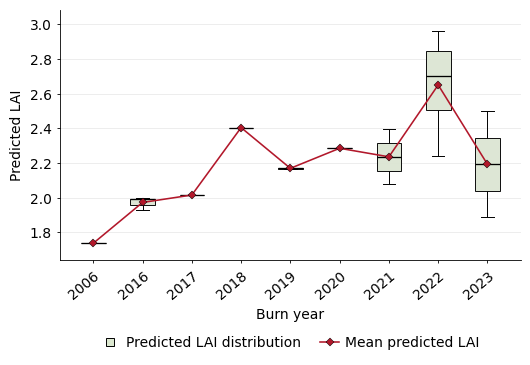

In [13]:
## C2. Predicted LAI across mapped burn-year classes

plot_df = fire_analysis_df.copy()
plot_df['Year'] = plot_df['Year'].astype(int)
burn_year_order = sorted(plot_df['Year'].dropna().astype(int).unique())

fig, ax = plt.subplots(figsize=(5.42, 4.11))
sns.boxplot(data=plot_df, x='Year', y='Mean_LAI', order=burn_year_order, ax=ax, color='#dce8d0', width=0.5, showfliers=False, linewidth=0.7, boxprops={'edgecolor': 'black', 'linewidth': 0.7, 'alpha': 0.95}, whiskerprops={'color': 'black', 'linewidth': 0.7}, capprops={'color': 'black', 'linewidth': 0.7}, medianprops={'color': 'black', 'linewidth': 0.95})
mean_by_year = plot_df.groupby('Year')['Mean_LAI'].mean().reindex(burn_year_order)
x_pos = np.arange(len(burn_year_order))
ax.plot(x_pos, mean_by_year.values, color='#b2182b', marker='D', markersize=3.8, markerfacecolor='#b2182b', markeredgecolor='black', markeredgewidth=0.35, linewidth=1.15, zorder=4)
y_min = plot_df['Mean_LAI'].min()
y_max = plot_df['Mean_LAI'].max()
y_range = y_max - y_min
ax.set_ylim(max(0, y_min - 0.08 * y_range), y_max + 0.1 * y_range)
ax.set_xlabel('Burn year')
ax.set_ylabel('Predicted LAI')
ax.set_xticks(x_pos)
ax.set_xticklabels([str(year) for year in burn_year_order], rotation=40, ha='right', rotation_mode='anchor')
ax.grid(True, axis='y', color='0.88', linewidth=0.4)
ax.grid(False, axis='x')
ax.set_axisbelow(True)
ax.tick_params(axis='both', length=2.5, width=0.6)
for spine in ax.spines.values():
    spine.set_linewidth(0.6)
sns.despine(ax=ax)
legend_handles = [Line2D([0], [0], marker='s', linestyle='none', markerfacecolor='#dce8d0', markeredgecolor='black', markeredgewidth=0.7, markersize=5.5, label='Predicted LAI distribution'), Line2D([0], [0], color='#b2182b', marker='D', markerfacecolor='#b2182b', markeredgecolor='black', markeredgewidth=0.35, linewidth=1.15, markersize=3.8, label='Mean predicted LAI')]
ax.legend(handles=legend_handles, loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=2, frameon=False, handlelength=1.35, handletextpad=0.45, columnspacing=1.4)
fig.subplots_adjust(left=0.13, right=0.98, bottom=0.34, top=0.95)
plt.show()

Landscape sampling units retained: 17
YSF reference year: 2023

Burn-year / YSF classes:
 Year  Years_Since_Fire
 2006                17
 2016                 7
 2017                 6
 2018                 5
 2019                 4
 2020                 3
 2021                 2
 2022                 1
 2023                 0

HSI indices to summarize: 28
Unique AVIRIS-NG channels required: 27

Computing raw HSI indices for ang20231031t092656_002 ...

Computing raw HSI indices for ang20231109t062226_001 ...

Computing raw HSI indices for ang20231109t062226_002 ...

Computing raw HSI indices for ang20231117t123306_001 ...

Polygon-level raw AVIRIS-NG index table:


,Poly_ID,Year,Years_Since_Fire,NDVI,SR,GNDVI,GRVI,GDVI,SAVI,GSAVI,OSAVI,MSAVI2,NDRE,SR_RE,CI_RE,MTCI,MSR,EVI2,NDWI,CAI,NDLI,Custom_SWIR_Primary,Custom_NIR_Plateau,Custom_VIS_Green,Custom_SWIR1_Bridge,NIRv,SATVI,NDTI,SINDRI,LCA,MTVI2
0,14,2023,0,0.4906,2.9777,0.5144,-0.0304,0.1479,0.2700,0.2805,0.3660,0.2389,0.2274,1.5910,0.5910,1.6263,0.7205,0.2556,-0.1317,-0.0131,0.0171,0.0120,0.0076,0.0599,-0.0030,0.1070,0.2438,0.1450,0.0479,5.6363,0.1722
1,15,2023,0,0.4472,2.9702,0.4697,-0.0176,0.1469,0.2531,0.2682,0.3380,0.2260,0.1999,1.5111,0.5111,1.4368,0.6857,0.2399,-0.1014,-0.0112,0.0204,-0.0284,0.0096,0.0585,-0.0003,0.1020,0.1863,0.1807,0.0696,6.5858,0.1604
2,13,2022,1,0.5166,3.2464,0.5286,-0.0135,0.1858,0.3187,0.3258,0.4103,0.2925,0.2379,1.6293,0.6293,1.7215,0.7918,0.3080,-0.0631,-0.0124,0.0205,0.0184,0.0051,0.0610,-0.0059,0.1385,0.2011,0.1656,0.0542,5.8935,0.2213
3,10,2022,1,0.5372,3.5330,0.5423,-0.0011,0.2182,0.3580,0.3617,0.4445,0.3379,0.2549,1.6944,0.6944,1.9617,0.8600,0.3521,-0.0159,-0.0103,0.0223,-0.0052,0.0062,0.0644,-0.0068,0.1673,0.1778,0.1850,0.0606,6.1989,0.2654
4,11,2022,1,0.6291,4.5132,0.5957,0.0568,0.1916,0.3643,0.3494,0.4835,0.3374,0.2704,1.7448,0.7448,1.7051,1.1149,0.3547,-0.0571,-0.0063,0.0224,0.0429,0.0066,0.0848,-0.0105,0.1619,0.2343,0.2030,0.0569,5.2415,0.2792
5,12,2022,1,0.6599,4.9587,0.6174,0.0740,0.2047,0.3883,0.3691,0.5117,0.3637,0.2751,1.7608,0.7608,1.6472,1.2214,0.3806,-0.0311,-0.0047,0.0263,0.0325,0.0082,0.0896,-0.0120,0.1771,0.2210,0.2344,0.0626,4.9774,0.3059
6,8,2021,2,0.6366,4.6878,0.6064,0.0541,0.1765,0.3462,0.3337,0.4720,0.3159,0.2762,1.7688,0.7688,1.6961,1.1515,0.3343,-0.0607,-0.0019,0.0251,0.0052,0.0110,0.0820,-0.0063,0.1494,0.2178,0.2424,0.0697,4.7985,0.2590
7,9,2021,2,0.5659,3.8153,0.5598,0.0156,0.1778,0.3269,0.3253,0.4339,0.2984,0.2624,1.7174,0.7174,1.8320,0.9356,0.3153,-0.0488,-0.0047,0.0257,-0.0159,0.0091,0.0656,-0.0057,0.1403,0.1938,0.2216,0.0695,5.3923,0.2351
8,7,2020,3,0.7184,6.3920,0.6668,0.1062,0.1871,0.3786,0.3584,0.5231,0.3498,0.3304,1.9951,0.9951,2.0934,1.5125,0.3680,-0.0101,0.0012,0.0263,-0.0021,0.0121,0.0905,-0.0100,0.1686,0.1858,0.3147,0.0867,3.8993,0.3015
9,5,2019,4,0.7331,6.6842,0.6754,0.1185,0.1741,0.3651,0.3439,0.5169,0.3326,0.3347,2.0134,1.0134,2.0750,1.5749,0.3523,-0.0036,0.0018,0.0262,-0.0096,0.0123,0.0884,-0.0100,0.1587,0.1689,0.3348,0.0906,3.4053,0.2892



Minimum valid pixel count by index across retained polygons:
NDVI                   545
SINDRI                 545
NDTI                   545
SATVI                  545
NIRv                   545
Custom_SWIR1_Bridge    545
Custom_VIS_Green       545
Custom_NIR_Plateau     545
Custom_SWIR_Primary    545
NDLI                   545
CAI                    545
NDWI                   545
EVI2                   545
MSR                    545
MTCI                   545
CI_RE                  545
SR_RE                  545
NDRE                   545
MSAVI2                 545
OSAVI                  545
GSAVI                  545
SAVI                   545
GDVI                   545
GRVI                   545
GNDVI                  545
SR                     545
LCA                    545
MTVI2                  545

Mean raw index value by years since fire (referenced to AVIRIS-NG 2023):
Years_Since_Fire         0       1       2       3       4       5       6       7       17
Custom_NIR_Plate

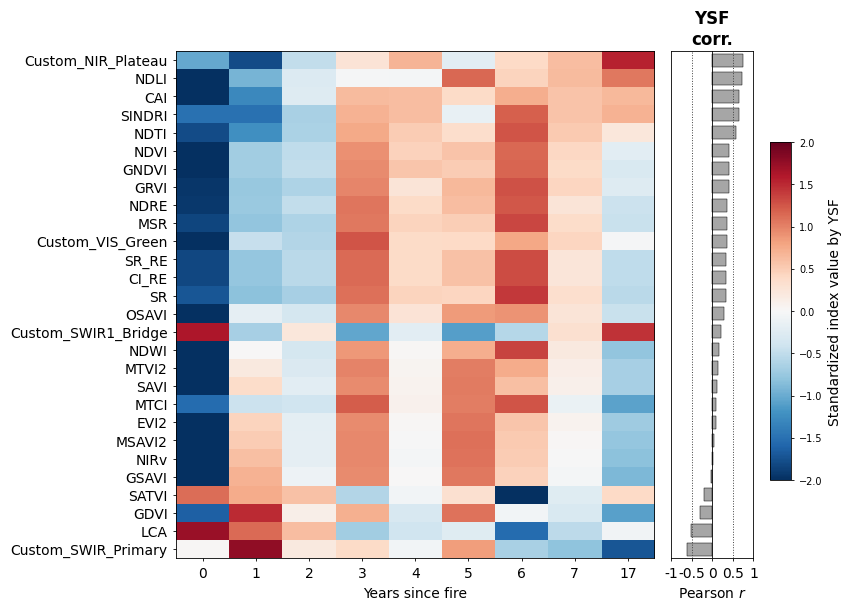

In [14]:
## D1. Supplementary: spectral variation across the post-fire age gradient

required_objects = ['AVIRIS_L2B', 'wavelengths', 'calculate_hsi_indices', 'HSI_INDEX_NAMES', 'fire_analysis_df', 'EPS']
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise NameError('Run the preceding revision-notebook cells first. Missing: ' + ', '.join(missing_objects))
fig_dir = Path('images')
fig_dir.mkdir(parents=True, exist_ok=True)

AVIRIS_ACQUISITION_YEAR = 2023
MIN_INDEX_PIXELS = int(globals().get('MIN_VALID_PIXELS_PER_FIRE_POLYGON', 10))
WINDOW_SIZE = 256
trend_gdf = fire_analysis_df[['fire_polygon_id', 'Year', 'geometry']].copy()
trend_gdf['Year'] = trend_gdf['Year'].astype(int)
trend_gdf['Years_Since_Fire'] = AVIRIS_ACQUISITION_YEAR - trend_gdf['Year']
if (trend_gdf['Years_Since_Fire'] < 0).any():
    bad_years = sorted(trend_gdf.loc[trend_gdf['Years_Since_Fire'] < 0, 'Year'].unique())
    raise ValueError(f'Burn years after the 2023 AVIRIS-NG acquisition were found: {bad_years}')
print(f'Landscape sampling units retained: {len(trend_gdf)}')
print(f'YSF reference year: {AVIRIS_ACQUISITION_YEAR}')
print('\nBurn-year / YSF classes:')
print(trend_gdf[['Year', 'Years_Since_Fire']].drop_duplicates().sort_values('Year').to_string(index=False))

index_target_wavelengths = [480, 527.4, 531, 547.4, 550, 570, 670, 681, 709, 720, 754, 800, 850, 860, 1240, 1243.6, 1288.7, 1650, 1680, 1729.5, 1749.5, 1750, 2005, 2100, 2210, 2260, 2320.5, 2330]
wavelengths_array = np.asarray(wavelengths, dtype=float)
selected_band_indices = sorted({int(np.argmin(np.abs(wavelengths_array - target))) for target in index_target_wavelengths})
selected_wavelengths = wavelengths_array[selected_band_indices]
index_names = list(HSI_INDEX_NAMES)
print(f'\nHSI indices to summarize: {len(index_names)}')
print(f'Unique AVIRIS-NG channels required: {len(selected_band_indices)}')
with TemporaryDirectory(prefix='aviris_hsi_index_trends_') as temp_dir:
    temp_dir = Path(temp_dir)
    temp_scene_paths = []
    for scene, nc_path in AVIRIS_L2B.items():
        print(f'\nComputing raw HSI indices for {scene} ...')
        subdataset = f'NETCDF:{nc_path}:/reflectance/reflectance'
        out_path = temp_dir / f"{str(scene).replace('/', '_')}_indices.tif"
        with rasterio.open(subdataset) as src:
            out_profile = {'driver': 'GTiff', 'height': src.height, 'width': src.width, 'count': len(index_names), 'dtype': 'float32', 'crs': src.crs, 'transform': src.transform, 'nodata': -9999.0, 'compress': 'deflate'}
            with rasterio.open(out_path, 'w', **out_profile) as dst:
                for row_off in range(0, src.height, WINDOW_SIZE):
                    win_h = min(WINDOW_SIZE, src.height - row_off)
                    for col_off in range(0, src.width, WINDOW_SIZE):
                        win_w = min(WINDOW_SIZE, src.width - col_off)
                        window = Window(col_off, row_off, win_w, win_h)
                        block_columns = []
                        for band_idx in selected_band_indices:
                            arr = src.read(band_idx + 1, window=window).astype(float)
                            valid = src.read_masks(band_idx + 1, window=window) > 0
                            valid &= np.isfinite(arr) & (arr > -50)
                            if src.nodata is not None:
                                valid &= arr != src.nodata
                            arr[~valid] = np.nan
                            block_columns.append(arr.reshape(-1))
                        X_block = np.column_stack(block_columns)
                        with np.errstate(divide='ignore', invalid='ignore', over='ignore'):
                            block_indices = calculate_hsi_indices(X_block, selected_wavelengths)
                        for out_band, index_name in enumerate(index_names, start=1):
                            arr_idx = np.asarray(block_indices[index_name], dtype=float).reshape(win_h, win_w)
                            arr_idx = np.where(np.isfinite(arr_idx), arr_idx, -9999.0).astype('float32')
                            dst.write(arr_idx, out_band, window=window)
        temp_scene_paths.append(out_path)
    scene_datasets = [rasterio.open(path) for path in temp_scene_paths]
    try:
        index_mosaic_crs = scene_datasets[0].crs
        trend_gdf = trend_gdf.to_crs(index_mosaic_crs)
        index_mean_table = trend_gdf[['fire_polygon_id', 'Year', 'Years_Since_Fire']].copy()
        index_count_table = trend_gdf[['fire_polygon_id']].copy()
        for band_number, index_name in enumerate(index_names, start=1):
            mosaic_index, mosaic_transform_index = merge(scene_datasets, indexes=[band_number], nodata=-9999.0, method='first')
            index_array = mosaic_index[0].astype(float)
            index_array[index_array == -9999.0] = np.nan
            index_for_stats = np.where(np.isfinite(index_array), index_array, -9999.0)
            stats = zonal_stats(trend_gdf.geometry, index_for_stats, affine=mosaic_transform_index, stats=['mean', 'count'], nodata=-9999.0)
            means = []
            counts = []
            for stat in stats:
                count = int(stat['count'] or 0)
                mean_value = stat['mean'] if count >= MIN_INDEX_PIXELS else np.nan
                means.append(mean_value)
                counts.append(count)
            index_mean_table[index_name] = means
            index_count_table[index_name] = counts
            del (mosaic_index, index_array, index_for_stats)
    finally:
        for ds in scene_datasets:
            ds.close()

df_all_trends = index_mean_table.rename(columns={'fire_polygon_id': 'Poly_ID'}).copy()
print('\nPolygon-level raw AVIRIS-NG index table:')
display(df_all_trends.round(4))
print('\nMinimum valid pixel count by index across retained polygons:')
print(index_count_table[index_names].min().sort_values().to_string())
ysf_order_all = sorted(df_all_trends['Years_Since_Fire'].dropna().astype(int).unique())
mean_traj = df_all_trends.groupby('Years_Since_Fire')[index_names].mean().reindex(ysf_order_all).T
valid_indices = mean_traj.index[mean_traj.notna().sum(axis=1).gt(1) & mean_traj.std(axis=1, skipna=True).gt(1e-09)]
mean_traj = mean_traj.loc[valid_indices]
z_traj = mean_traj.sub(mean_traj.mean(axis=1), axis=0)
z_traj = z_traj.div(mean_traj.std(axis=1), axis=0)
corr_records = []
for idx in mean_traj.index:
    valid = np.isfinite(df_all_trends[idx]) & np.isfinite(df_all_trends['Years_Since_Fire'])
    n_valid = int(valid.sum())
    if n_valid < 4:
        r = np.nan
        p_val = np.nan
    else:
        r, p_val = pearsonr(df_all_trends.loc[valid, 'Years_Since_Fire'], df_all_trends.loc[valid, idx])
    corr_records.append({'Index': idx, 'r': r, 'p': p_val, 'abs_r': abs(r) if np.isfinite(r) else np.nan, 'n': n_valid})

corr_df = pd.DataFrame(corr_records).set_index('Index')
ordered_indices = corr_df.loc[z_traj.index].sort_values('r', ascending=False).index
z_traj = z_traj.loc[ordered_indices]
mean_traj = mean_traj.loc[ordered_indices]
corr_df = corr_df.loc[ordered_indices]
print('\nMean raw index value by years since fire (referenced to AVIRIS-NG 2023):')
print(mean_traj.round(4).to_string())
print('\nPearson correlation of raw HSI indices with years since fire:')
print(corr_df[['r', 'p', 'n']].sort_values('r', ascending=False).round(4).to_string())
print('\nTop indices by absolute Pearson correlation with years since fire:')
print(corr_df.sort_values('abs_r', ascending=False)[['r', 'p', 'n']].head(10).round(4).to_string())

fig = plt.figure(figsize=(8.25, 6.5))
ax_heat = fig.add_axes([0.18, 0.12, 0.58, 0.78])
ax_corr = fig.add_axes([0.78, 0.12, 0.1, 0.78])
cax = fig.add_axes([0.9, 0.24, 0.025, 0.52])
cmap = mpl.cm.RdBu_r
norm = mcolors.TwoSlopeNorm(vmin=-2, vcenter=0, vmax=2)
im = ax_heat.imshow(z_traj.values, aspect='auto', cmap=cmap, norm=norm, interpolation='nearest')
ax_heat.grid(False)
ax_heat.minorticks_off()
ax_heat.set_xticks(np.arange(len(ysf_order_all)))
ax_heat.set_xticklabels(ysf_order_all)
ax_heat.set_yticks(np.arange(len(z_traj.index)))
ax_heat.set_yticklabels(z_traj.index)
ax_heat.set_xlabel('Years since fire')
ax_heat.set_ylabel('')
ax_heat.tick_params(axis='both', length=2.5, width=0.6)
for spine in ax_heat.spines.values():
    spine.set_linewidth(0.6)
r_vals = corr_df['r'].values
ax_corr.barh(np.arange(len(r_vals)), r_vals, color='0.65', edgecolor='black', linewidth=0.35, height=0.72)
ax_corr.axvline(0, color='black', linewidth=0.6)
ax_corr.axvline(-0.5, color='0.25', linewidth=0.7, linestyle=':')
ax_corr.axvline(0.5, color='0.25', linewidth=0.7, linestyle=':')
ax_corr.set_ylim(ax_heat.get_ylim())
ax_corr.set_xlim(-1, 1)
ax_corr.set_xticks([-1, -0.5, 0, 0.5, 1])
ax_corr.set_xticklabels(['-1', '-0.5', '0', '0.5', '1'])
ax_corr.set_yticks([])
ax_corr.set_xlabel('Pearson $r$')
ax_corr.set_title('YSF\ncorr.', fontweight='bold', pad=5)
ax_corr.grid(False)
ax_corr.minorticks_off()
ax_corr.tick_params(axis='x', length=2.5, width=0.6)
for spine in ax_corr.spines.values():
    spine.set_linewidth(0.6)
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('Standardized index value by YSF')
cbar.ax.tick_params(labelsize=7, length=2.5, width=0.6)
cbar.outline.set_linewidth(0.6)
plt.show()

In [15]:
## D2. Supplementary: UAS valid four-band coverage summary

coverage_rows = []
for site, uas_path in UAS_FILES.items():
    with rasterio.open(uas_path) as src:
        pixel_area_map_units = abs(src.transform.a * src.transform.e - src.transform.b * src.transform.d)
        if src.crs is None or not src.crs.is_projected:
            raise ValueError(f'{site}: raster is not in a projected CRS: {src.crs}')
        pixel_area_m2 = float(pixel_area_map_units)
        total_pixels = src.width * src.height
        rectangular_area_ha = total_pixels * pixel_area_m2 / 10000.0
        band_masks = src.read_masks()
        valid_mask = np.all(band_masks > 0, axis=0)
        data = src.read(masked=False).astype(float)
        valid_mask &= np.all(np.isfinite(data), axis=0)
        if src.nodata is not None:
            valid_mask &= np.all(data != src.nodata, axis=0)
        valid_pixels = int(np.count_nonzero(valid_mask))
        valid_area_ha = valid_pixels * pixel_area_m2 / 10000.0
        valid_fraction = valid_pixels / total_pixels if total_pixels > 0 else np.nan
        coverage_rows.append({'Site': site, 'Width_px': src.width, 'Height_px': src.height, 'Pixel_size_x_m': abs(src.transform.a), 'Pixel_size_y_m': abs(src.transform.e), 'Rectangular_area_ha': rectangular_area_ha, 'Valid_area_ha': valid_area_ha, 'Valid_fraction': valid_fraction, 'CRS': str(src.crs)})

uas_coverage_df = pd.DataFrame(coverage_rows)
uas_coverage_df['Valid_fraction_pct'] = 100.0 * uas_coverage_df['Valid_fraction']
uas_coverage_df = uas_coverage_df.sort_values('Site').reset_index(drop=True)
display(uas_coverage_df[['Site', 'Pixel_size_x_m', 'Pixel_size_y_m', 'Rectangular_area_ha', 'Valid_area_ha', 'Valid_fraction_pct', 'CRS']].round(3))
print(f"\nValid UAS coverage range: {uas_coverage_df['Valid_area_ha'].min():.2f}–{uas_coverage_df['Valid_area_ha'].max():.2f} ha")

,Site,Pixel_size_x_m,Pixel_size_y_m,Rectangular_area_ha,Valid_area_ha,Valid_fraction_pct,CRS
0,BY_2006,0.030,0.030,3.432,2.618,76.297,EPSG:32734
1,BY_2016,0.022,0.022,2.652,2.054,77.473,EPSG:32734
2,BY_2017_16,0.022,0.022,2.650,2.018,76.151,EPSG:32734
3,BY_2019,0.022,0.022,2.367,1.881,79.459,EPSG:32734
4,BY_2020,0.018,0.018,2.027,1.483,73.175,EPSG:32734



Valid UAS coverage range: 1.48–2.62 ha
